# 3.2 Prediction-level late fusion outperforms feature-level joint fusion

**Figure 2** (MAP vs single-backbone references vs late fusion), **Figures S1–S3** (per-task aggregation views), **Table S2** (aggregation comparison), **Figure 3** (ensemble-size sweep), **Table S3** (k-sweep). Recomputed from `../data/recompute_data/` via the shared setup cell.

In [1]:
# === Setup: figure/table regeneration for the ADMET multi-representation fusion paper ===
# Self-contained RECOMPUTATION from source predictions.
# Every figure/table quantity is recomputed here from raw per-seed per-molecule predictions
# (recompute_data/predictions/{model}.parquet), the per-model TDC leaderboard rankings
# (recompute_data/leaderboards/{model}.csv, direct training outputs), the 1023-subset uniform
# fusion sweep (recompute_data/all1023.csv), and the leaderboard
# ruler (recompute_data/tdc_leaderboard_snapshot.json). Nothing below is a hard-coded result;
# task metadata (ADMET group, training-set size, mechanism rationale) is loaded from
# recompute_data/task_metadata.json (fixed design labels, not recomputed). assert blocks verify the recomputed numbers against the
# manuscript values.
import os, json, io, itertools
from math import factorial
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr, kendalltau, wilcoxon
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error
from statsmodels.stats.multitest import multipletests

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
RELDATA = os.path.join(HERE, "..", "data")          # release data/ dir (single canonical copy)
DATA = os.path.join(RELDATA, "recompute_data")
OUTDIR = os.path.join(HERE, "..", "figures"); os.makedirs(OUTDIR, exist_ok=True)  # write figures into release figures/ dir
META_GREY = "#888888"

def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    import matplotlib as mpl
    if frame not in ("open", "boxed", "none"):
        raise ValueError(f"frame must be 'open'|'boxed'|'none', got {frame!r}")
    try:
        import os, sys, glob, matplotlib.font_manager as fm
        fdir = os.path.join(os.environ.get("CONDA_PREFIX") or sys.prefix, "fonts")
        if os.path.isdir(fdir):
            known = {f.fname for f in fm.fontManager.ttflist}
            for f in glob.glob(os.path.join(fdir, "*.ttf")):
                if f not in known:
                    fm.fontManager.addfont(f)
    except Exception:
        pass
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif", "font.size": base, "axes.labelsize": base,
        "axes.titlesize": base, "legend.fontsize": secondary, "xtick.labelsize": tick,
        "ytick.labelsize": tick, "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid), "legend.frameon": False,
        "figure.dpi": 200, "savefig.dpi": 300, "savefig.bbox": "tight",
        "axes.titleweight": "normal", "axes.titlelocation": "left",
        "axes.labelweight": "normal", "lines.linewidth": 1.2, "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)

REG  = json.load(open(f"{DATA}/task_registry.json"))
SNAP = json.load(open(f"{DATA}/tdc_leaderboard_snapshot.json"))
MODELS = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
TASKS  = [t for t in REG if t != "Bioavailability_Ma"]  # 21 evaluation tasks

def metric(name, y, p):
    """Compute a single TDC metric (mae/auroc/auprc/spearman) after dropping NaN labels."""
    y = np.asarray(y, float); p = np.asarray(p, float); m = ~np.isnan(y); y, p = y[m], p[m]
    if name == "mae":      return float(mean_absolute_error(y, p))
    if name == "auroc":    return float(roc_auc_score(y, p))
    if name == "auprc":    return float(average_precision_score(y, p))
    if name == "spearman": return float(spearmanr(y, p)[0])
    raise KeyError(name)

def norm_pct(score, task):
    """norm_score = fraction of TDC leaderboard models we beat (metric-direction aware)."""
    e = SNAP.get(task)
    if e is None or np.isnan(score): return np.nan
    s = [m["score"] for m in e["models"].values()]; met = REG[task]["metric"]
    worse = (sum(1 for x in s if x > score) if met == "mae" else sum(1 for x in s if x < score))
    return worse / len(s)

def rank_of(score, task):
    """Leaderboard rank of `score` for `task` (1 = best), metric-direction aware."""
    e = SNAP.get(task); met = REG[task]["metric"]
    s = [m["score"] for m in e["models"].values()]
    return (sum(1 for x in s if x < score) if met == "mae" else sum(1 for x in s if x > score)) + 1

# ---- load predictions (add replicate counter for exact merge keys) ----
PRED = {}
for m in MODELS:
    d = pd.read_parquet(f"{DATA}/predictions/{m}.parquet")
    PRED[m] = d.assign(rep=d.groupby(["seed","task","split","smiles"]).cumcount())

def merge_uniform(models, within):
    """Inner-join the given models' per-molecule predictions; add `yhat` = their uniform mean.
    within=True keeps the seed axis (matched-seed track); within=False averages predictions
    across seeds first (seed-averaged track). Returns the merged long DataFrame."""
    keys = ["seed","task","split","smiles","rep"] if within else ["task","split","smiles","rep"]
    if within:
        base = PRED[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(PRED[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    else:
        sm = {m: PRED[m].groupby(["task","split","smiles","rep"])
                       .agg(y_true=("y_true","first"), y_pred=("y_pred","mean")).reset_index() for m in models}
        base = sm[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(sm[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    base["yhat"] = base[[f"p_{m}" for m in models]].mean(axis=1)
    return base

def pertask_norm(models, within):
    """{task: norm_score} for the uniform-mean fusion of `models`, on the held-out test set.
    within=True: average the per-seed raw metric, then normalize once; within=False: score once on
    the seed-averaged predictions."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            seed_sc = [metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]
            res[task] = norm_pct(float(np.mean(seed_sc)), task)
        else:
            res[task] = norm_pct(metric(met, t.y_true, t.yhat), task)
    return res

def pertask_raw(models, within):
    """{task: raw_score} for the uniform-mean fusion of `models`, held-out test set.
    Mirror of pertask_norm but returns the raw metric value (before leaderboard normalization).
    within=True: mean over the per-seed metric (matched-seed track)."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            res[task] = float(np.mean([metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]))
        else:
            res[task] = float(metric(met, t.y_true, t.yhat))
    return res

def subset_norm(models, within):
    """Mean of pertask_norm across the 21 evaluation tasks (one scalar per subset)."""
    return float(np.mean(list(pertask_norm(models, within).values())))

# ---- correlation matrices (exact XAI method) ----
def corr_matrices(within):
    """Mean off-diagonal |correlation| among the k=5 ensemble members, for both the
    standardized predictions and the standardized residuals (prediction - truth).

    Returns (pred_corr, resid_corr): how redundant the members' outputs / errors are.
    within=True  -> matched-seed track: correlate per (task, seed), average the matrices.
    within=False -> seed-averaged track: pool all test rows per task, correlate once.
    (This is the exact 'XAI' correlation recipe used in the analysis notebooks.)
    """
    pred_cols = [f"p_{m}" for m in ENSEMBLE]
    base = merge_uniform(ENSEMBLE, within)
    if not within:
        # seed-averaged: concatenate standardized vectors across all tasks, one corr matrix
        pred_z  = {m: [] for m in ENSEMBLE}   # standardized predictions per member
        resid_z = {m: [] for m in ENSEMBLE}   # standardized residuals per member
        for task in TASKS:
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            for j, m in enumerate(ENSEMBLE):
                p = preds[:, j]; pred_z[m].append((p - p.mean())/(p.std()+1e-9))
                resid = p - y_true; resid_z[m].append((resid - resid.mean())/(resid.std()+1e-9))
        pred_z  = {m: np.concatenate(v) for m, v in pred_z.items()}
        resid_z = {m: np.concatenate(v) for m, v in resid_z.items()}
        pred_corr_mat  = np.corrcoef([pred_z[m]  for m in ENSEMBLE])
        resid_corr_mat = np.corrcoef([resid_z[m] for m in ENSEMBLE])
    else:
        # matched-seed: one corr matrix per (task, seed), then average across all of them
        seeds = sorted(base.seed.unique()); pred_mats = []; resid_mats = []
        for task in TASKS:
            task_rows = base[base.task==task]
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows) < 3: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                pred_z_seed = []; resid_z_seed = []
                for j, m in enumerate(ENSEMBLE):
                    p = preds[:, j]
                    pred_z_seed.append((p - p.mean())/(p.std()+1e-9))
                    resid_z_seed.append((p - y_true) - (p - y_true).mean()/((p - y_true).std()+1e-9))
                pred_mats.append(np.corrcoef(pred_z_seed)); resid_mats.append(np.corrcoef(resid_z_seed))
        pred_corr_mat  = np.nanmean(pred_mats, 0)
        resid_corr_mat = np.nanmean(resid_mats, 0)
    upper = np.triu_indices(len(ENSEMBLE), 1)   # off-diagonal (unordered pairs)
    return float(np.abs(pred_corr_mat[upper]).mean()), float(np.abs(resid_corr_mat[upper]).mean())

# ---- winners + best-single mean rank ----
def winners_best(within):
    """Per-task winner counts among the k=5 members + the best single member's mean TDC rank.

    Returns (wins, best_model, best_mean_rank):
      wins           - {model: number of tasks where it is the single best member}
      best_model     - member with the lowest mean leaderboard rank across tasks
      best_mean_rank - that member's mean rank (the single-model baseline the ensemble beats)
    within=True  -> matched-seed: winner decided per (task, seed); rank from seed-mean score.
    within=False -> seed-averaged: winner decided once per task on the seed-averaged score.
    """
    from collections import Counter
    base = merge_uniform(ENSEMBLE, within); pred_cols = [f"p_{m}" for m in ENSEMBLE]
    if not within:
        wins = Counter(); member_ranks = {m: [] for m in ENSEMBLE}   # per-task leaderboard rank
        for task in TASKS:
            met = REG[task]["metric"]
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
            wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
            for m in ENSEMBLE: member_ranks[m].append(rank_of(member_score[m], task))
    else:
        seeds = sorted(base.seed.unique()); wins = Counter(); member_score_by_task = {m: [] for m in ENSEMBLE}
        for task in TASKS:
            met = REG[task]["metric"]; task_rows = base[base.task==task]; seed_scores = {m: [] for m in ENSEMBLE}
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows)==0: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
                wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
                for m in ENSEMBLE: seed_scores[m].append(member_score[m])
            for m in ENSEMBLE: member_score_by_task[m].append(np.mean(seed_scores[m]))
        member_ranks = {m: [rank_of(member_score_by_task[m][i], TASKS[i]) for i in range(len(TASKS))] for m in ENSEMBLE}
    best_model = min(ENSEMBLE, key=lambda m: np.mean(member_ranks[m]))
    return dict(wins), best_model, float(np.mean(member_ranks[best_model]))

# ---- ensemble mean TDC rank (Score-then-Rank), within + cross ----
def ensemble_mean_rank():
    """Mean TDC leaderboard rank of the k=5 ensemble across tasks (Score-then-Rank).
    Returns (mean_rank_within, mean_rank_cross)."""
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False)
    ranks_w = []; ranks_c = []
    for task in TASKS:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ranks_w.append(rank_of(float(np.mean(seed_sc)), task))
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        ranks_c.append(rank_of(metric(met, tc.y_true, tc.yhat), task))
    return float(np.mean(ranks_w)), float(np.mean(ranks_c))

# ---- LOO + Shapley (over all 31 non-empty subsets of ENSEMBLE) ----
def loo_shapley():
    """Leave-one-out and Shapley contribution of each k=5 member to the ensemble norm_score.

    Enumerates all 31 non-empty subsets of ENSEMBLE and scores each (within + cross track):
      loo_within/cross    = value(full) - value(full minus this member)  (removal effect)
      shapley_within/cross= mean marginal contribution over all coalitions (Shapley value)
    Returns (per_member_dict, value_full_within, value_full_cross).
    """
    value_within = {}; value_cross = {}
    for size in range(1, len(ENSEMBLE)+1):
        for combo in itertools.combinations(ENSEMBLE, size):
            key = tuple(sorted(combo))
            value_within[key] = subset_norm(list(combo), True)
            value_cross[key]  = subset_norm(list(combo), False)
    full = tuple(sorted(ENSEMBLE)); n_members = len(ENSEMBLE)
    def shapley(value):
        contrib = {m: 0.0 for m in ENSEMBLE}
        for m in ENSEMBLE:
            others = [x for x in ENSEMBLE if x != m]
            for size in range(len(others)+1):
                for coalition in itertools.combinations(others, size):
                    weight = factorial(len(coalition))*factorial(n_members-len(coalition)-1)/factorial(n_members)
                    with_m    = value[tuple(sorted(coalition+(m,)))]
                    without_m = value[tuple(sorted(coalition))] if coalition else 0.0
                    contrib[m] += weight*(with_m - without_m)
        return contrib
    shap_within = shapley(value_within); shap_cross = shapley(value_cross); out = {}
    for m in ENSEMBLE:
        out[m] = {
            "within_solo": value_within[(m,)],
            "loo_within":  value_within[full] - value_within[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "cross_solo":  value_cross[(m,)],
            "loo_cross":   value_cross[full]  - value_cross[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "shapley_within": shap_within[m], "shapley_cross": shap_cross[m]}
    return out, value_within[full], value_cross[full]

# ---- MAP vs mean/max aggregation (leaderboard.csv `ours` -> re-ranked) ----
def map_agg():
    """MAP (joint latent fusion) vs naive mean/best aggregation of the 3 shared backbones,
    per training regime (mtl/stl). Uses leaderboard.csv `ours` scores re-normalized against
    the TDC snapshot. Returns (summary_dict, long_leaderboard_df)."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    def to_norm(ds, score):
        e = SNAP.get(ds)
        if e is None or pd.isna(score): return np.nan
        met = REG[ds]["metric"]; s = [x["score"] for x in e["models"].values()]
        rank = (sum(1 for x in s if x < score) if met=="mae" else sum(1 for x in s if x > score))+1
        return (len(s)-rank+1)/len(s)
    BACKS = ["chemeleon","graphmvp","molformer"]; res = {}
    for train in ["mtl","stl"]:
        bm = [f"{train}_{b}" for b in BACKS]
        piv = LONG[LONG.model.isin(bm)].pivot_table(index=["dataset","metric"], columns="model", values="ours", aggfunc="first")
        mp = LONG[LONG.model==f"{train}_map"].set_index("dataset").apply(lambda r: to_norm(r.name, r["ours"]), axis=1)
        mn = {}; mx = {}
        for (ds,met),row in piv.iterrows():
            vals = row[bm].dropna()
            if vals.empty: continue
            direction = SNAP.get(ds,{}).get("direction","higher")
            mn[ds] = to_norm(ds, vals.mean()); mx[ds] = to_norm(ds, vals.max() if direction=="higher" else vals.min())
        common = [d for d in mp.index if d in mn]
        mpv = mp[common]; mnv = pd.Series(mn)[common]; mxv = pd.Series(mx)[common]
        res[train] = {"map":round(float(mpv.mean()),3),"mean":round(float(mnv.mean()),3),"best":round(float(mxv.mean()),3),
                      "map_gt_mean":f"{int((mpv>mnv).sum())}/{len(common)}",
                      "map_gt_best":f"{int((mpv>mxv).sum())}/{len(common)}","n":len(common)}
    return res, LONG

# ---- ensemble-size sweep (top-20 mean per k over 1023 uniform subsets) ----
def ksweep():
    # all1023.csv: the uniform-mean fusion sweep over all 1,023 non-empty subsets of the 10
    #   base models, scored on both validation and the held-out TDC test split (matched-seed
    #   'within' and seed-averaged 'cross' tracks). One row per subset; columns:
    #   combo_key (comma-joined member list), k, {val,test}_{within,cross}, {val,test}_comb.
    #   The ensemble-size selection uses the VALIDATION columns only (val_within/val_cross);
    #   the test columns are the same file's source for the Figure 5 reliability scatter.
    #   Feeds Figure 3 + Table S3 (validation top-20-mean norm_score per k -> elbow at k=5).
    #   This file is fully regenerable from the 10 predictions/*.parquet via code/make_all1023.py
    #   (predictions -> script -> csv closure); nothing here is hard-coded.
    s1 = pd.read_csv(f"{DATA}/all1023.csv")
    s1["k"] = s1.combo_key.apply(lambda b: len(b.split(",")))
    def topN(col, N=20):
        return {k: round(s1[s1.k==k].nlargest(min(N,(s1.k==k).sum()), col)[col].mean(),4) for k in range(1,11)}
    tw = topN("val_within"); tc = topN("val_cross")
    rows = []
    for k in range(1,11):
        rows.append([k, tw[k], round(tw[k]-tw[k-1],4) if k>1 else None,
                        tc[k], round(tc[k]-tc[k-1],4) if k>1 else None])
    return rows

# ---- validation->test rank reliability (all 1023 subsets) ----
def val_test_corr():
    # all1023.csv: uniform-mean fusion scored on BOTH validation and the fixed TDC test set,
    #   for every one of the 1,023 non-empty subsets. One row per subset; columns:
    #   combo_key (member list), k, val_within, val_cross, test_within, test_cross,
    #   val_comb, test_comb. This is the source for Figure 4a's validation->test rank
    #   reliability scatter, which uses the val_* -> test_* columns of the same sweep file.
    #   Same source as ksweep() (Figure 3); regenerable via code/make_all1023.py.
    from scipy.stats import spearmanr as _sp, kendalltau as _kt
    a = pd.read_csv(f"{DATA}/all1023.csv"); out = {}
    for name,vc,tc in [("within","val_within","test_within"),("cross","val_cross","test_cross"),("combined","val_comb","test_comb")]:
        out[name] = {"rho": round(_sp(a[vc],a[tc])[0],4), "tau": round(_kt(a[vc],a[tc])[0],4)}
    out["n_configs"] = len(a); return out

# ---- statistical tests (ensemble vs deployable singles + per-task oracle) ----
def stat_tests():
    ens_w = pertask_norm(ENSEMBLE, True); ens_c = pertask_norm(ENSEMBLE, False)
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    LONG["norm"] = (LONG.n_total - LONG["rank"] + 1)/LONG.n_total
    lbp = LONG.pivot_table(index="dataset", columns="model", values="norm").loc[TASKS]
    baselines = {"CheMeleon\u00b7STL":"stl_chemeleon","MAP\u00b7STL":"stl_map","D-MPNN\u00b7MTL":"mtl_dmpnn"}
    dep = {}; ora = {}
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        e = np.array([ens[t] for t in TASKS])
        for disp, m in baselines.items():
            b = lbp[m].to_numpy(); de = e - b; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
            dep[f"{disp}|{track}"] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
                "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(b.mean())}
        oc = lbp.max(axis=1).to_numpy(); de = e - oc; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
        ora[track] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
            "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(oc.mean())}
    return {"deployable_single":dep, "per_task_oracle":ora, "n_tasks":len(TASKS),
            "ensemble_mean":{"within":float(np.mean(list(ens_w.values()))),"cross":float(np.mean(list(ens_c.values())))}}

# ---- per-task tables t1 (per-backbone), t3 (MAP/mean/max), t4 (ensemble) ----
def leaderboard_long():
    """Concatenate every model's leaderboard.csv into one long frame with a `norm` column."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    L = pd.concat(lbs, ignore_index=True)
    L["norm"] = (L.n_total - L["rank"] + 1)/L.n_total
    return L

def table_t1(meta):
    """per-backbone per-task raw+norm on the WITHIN-SEED (matched-seed) basis: each seed is
    scored separately, the five raw scores are averaged, and that mean is normalized once (identical
    basis to Figure 1a / Table 3). meta = {task:{group,n}}. norm rounded to 3 decimals."""
    BB = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
    raw = {b: pertask_raw([b], True)  for b in BB}
    nrm = {b: pertask_norm([b], True) for b in BB}
    rows = []
    for task, mrec in meta.items():
        e = {"group": mrec["group"], "dataset": task, "n": mrec["n"], "metric": REG[task]["metric"]}
        for b in BB:
            e[b] = {"raw": round(float(raw[b][task]),3), "norm": round(float(nrm[b][task]),3)}
        rows.append(e)
    return rows

def table_t3(meta3):
    """MAP / latent-mean / latent-best per-task raw+norm on the WITHIN-SEED basis. MAP is the
    joint-fusion model's own per-seed prediction; latent mean/best aggregate the three backbones'
    per-seed scores (mean or direction-aware best) per seed, then norm and average. meta3 = {task:{group}}."""
    BACKS = ["chemeleon","graphmvp","molformer"]
    def agg_within(train, task, how):
        # Reference lines for the three MAP backbones, on the SAME basis as every other
        # normalized value in this release (Method A): aggregate in RAW score space first,
        # normalize exactly once at the end.
        #   step 1  per encoder, average the raw metric over the five seeds (= its Table S1 value)
        #   step 2  across the three encoders take the mean, or the best in the metric direction
        #   step 3  map that single raw value through norm_pct once
        # Aggregating inside each seed and normalizing per seed instead would make `best` a
        # per-seed oracle whose raw value matches no individual backbone, and would break
        # monotonicity between the raw and normalized columns because norm_pct is a step
        # function of the raw metric.
        met = REG[task]["metric"]
        enc_raw = {}
        for bb in BACKS:
            d = PRED[f"{train}_{bb}"]
            per_seed = []
            for seed in sorted(d.seed.unique()):
                t = d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
                per_seed.append(metric(met, t.y_true, t.y_pred))
            enc_raw[bb] = float(np.mean(per_seed))
        vals = list(enc_raw.values())
        raw = float(np.mean(vals)) if how=="mean" else float(min(vals) if met=="mae" else max(vals))
        return raw, float(norm_pct(raw, task))
    map_raw = {tr: pertask_raw([f"{tr}_map"], True)  for tr in ["mtl","stl"]}
    map_nrm = {tr: pertask_norm([f"{tr}_map"], True) for tr in ["mtl","stl"]}
    rows = []
    for task, mrec in meta3.items():
        met = REG[task]["metric"]; e = {"group": mrec["group"], "dataset": task, "metric": met}
        for train in ["mtl","stl"]:
            e[f"{train}_map"]  = {"raw": round(float(map_raw[train][task]),3), "norm": round(float(map_nrm[train][task]),3)}
            mr, mn = agg_within(train, task, "mean"); br, bn = agg_within(train, task, "best")
            e[f"{train}_mean"] = {"raw": round(mr,3), "norm": round(mn,3)}
            e[f"{train}_best"] = {"raw": round(br,3), "norm": round(bn,3)}
        rows.append(e)
    return rows

def table_t4():
    """ensemble per-task within/cross score+norm+rank over ALL 22 tasks (incl Bioavailability_Ma)."""
    allt = list(REG)
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False); rows = []
    for task in allt:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ws = float(np.mean(seed_sc)); ws_std = float(np.std(seed_sc, ddof=0))  # ddof=0 matches TDC ours_std
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        cs = metric(met, tc.y_true, tc.yhat)
        def _n(x, nd=3):  # int for exact 0/1 (match hardcoded schema), else float rounded to nd
            return int(x) if float(x).is_integer() else round(float(x), nd)
        rows.append({"task":task, "metric":met,
                     "within_score":round(ws,6), "within_std":round(ws_std,6), "within_norm":_n(norm_pct(ws,task),3), "within_rank":rank_of(ws,task),
                     "cross_score":round(cs,6),  "cross_norm":_n(norm_pct(cs,task),3),  "cross_rank":rank_of(cs,task)})
    return rows

# ---- Figure-1 within-seed solo + per-task (predictions basis) ----
def fig1_data(groups):
    """Figure 1 inputs on the within-seed (matched-seed) basis: per-model solo norm_score
    (`solo`), per-model per-task norm (`pertask`), and the ADMET mechanism `groups`."""
    solo = {m: subset_norm([m], True) for m in MODELS}
    pertask = []
    for task in TASKS:
        rec = {"task": task}
        for m in MODELS:
            rec[m] = pertask_norm([m], True)[task]
        pertask.append(rec)
    return {"solo": solo, "pertask": pertask, "groups": groups}

# ---- assemble full _GT / _PT / _FIG1 / _ST ----
def build_all(meta1, meta3, groups, t2, const_gt):
    lo, ens_w, ens_c = loo_shapley()
    cw = corr_matrices(True); cc = corr_matrices(False)
    win_w, bs_w, bsr_w = winners_best(True); win_c, bs_c, bsr_c = winners_best(False)
    mag, _ = map_agg()
    GT = dict(const_gt)  # final_ensemble, headline, sota_tasks, etc (constants)
    GT["map_agg"] = {t: {k: mag[t][k] for k in ["map","mean","best","map_gt_mean","map_gt_best"]} for t in ["mtl","stl"]}
    GT["ksweep"] = ksweep()
    GT["corr"] = {"within": {"pred_offdiag": round(cw[0],3), "resid_offdiag": round(cw[1],3)},
                  "cross":  {"pred_offdiag": round(cc[0],3), "resid_offdiag": round(cc[1],3)}}
    # ens_rank = mean TDC rank of the k=5 uniform ensemble across the 21 tasks (Score-then-Rank),
    # recomputed here (NOT a literal): within uses per-seed→mean→rank, cross uses seed-meaned→rank.
    ens_rank_w, ens_rank_c = ensemble_mean_rank()
    GT["best_single"] = {"within": {"model": bs_w, "mean_rank": round(bsr_w,3), "ens_rank": round(ens_rank_w,3)},
                         "cross":  {"model": bs_c, "mean_rank": round(bsr_c,3), "ens_rank": round(ens_rank_c,3)}}
    # per member -> [0]=within_solo  [1]=loo_within  [2]=cross_solo
    #                [3]=loo_cross    [4]=shapley_within  [5]=shapley_cross
    GT["loo_shapley"] = {b: [round(lo[b]["within_solo"],4), round(lo[b]["loo_within"],4),
                             round(lo[b]["cross_solo"],4), round(lo[b]["loo_cross"],4),
                             round(lo[b]["shapley_within"],4), round(lo[b]["shapley_cross"],4)] for b in ENSEMBLE}
    GT["winners"] = {"cross": {m: win_c.get(m,0) for m in ENSEMBLE},
                     "within_taskseed": {m: win_w.get(m,0) for m in ENSEMBLE}}
    GT["full_ensemble_norm"] = {"within": round(ens_w,4), "cross": round(ens_c,4)}
    PT = {"t1": table_t1(meta1), "t3": table_t3(meta3), "t4": table_t4(), "t2": t2}
    FIG1 = fig1_data(groups)
    ST = stat_tests()
    return GT, PT, FIG1, ST


# --- task metadata (fixed design labels, not recomputed): loaded from recompute_data/task_metadata.json ---
_TASK_META = json.load(open(f"{DATA}/task_metadata.json"))
_META1   = _TASK_META["meta1"]                                   # {task: {group, n}}
_META3   = {t: {"group": v["group"]} for t, v in _META1.items()} # meta1 without training-set size
_GROUPS  = _TASK_META["groups"]                                  # {mechanism group: [tasks]}
_T2      = _TASK_META["t2"]                                      # [{group, tasks, rationale}]
_CONST_GT = _TASK_META["const_gt"]                               # final_ensemble / final_composition / ...
ENSEMBLE  = list(_CONST_GT["final_ensemble"])                    # final k=5 members (single source of truth)


# --- recompute everything from source ---
_GT, _PT, _FIG1, _ST = build_all(_META1, _META3, _GROUPS, _T2, _CONST_GT)

# --- solo per-task within/cross norm (recomputed from predictions+leaderboards; replaces solo_pertask_within_cross.csv / fig1_within_pertask.csv) ---
# Per-(model, task) solo within/cross norm_score, recomputed from source predictions +
# leaderboard rankings. Replaces the released solo_pertask_within_cross.csv and
# fig1_within_pertask.csv (values verified identical to 1e-16).
# Row order matters ONLY for Figure 4d's winner-per-task argmax under exact norm ties
# (several tasks tie to the 4th decimal); we emit rows in the exact model/task order of
# the original fig1_within_pertask.csv so idxmax tie-breaking reproduces the published
# Figure 4d winner distribution (8/5/4/3/1). The norm values themselves are order-independent.
_SOLO_MODEL_ORDER = ["mtl_dmpnn","stl_dmpnn","stl_map","stl_chemeleon","stl_graphmvp",
                     "stl_molformer","mtl_graphmvp","mtl_molformer","mtl_chemeleon","mtl_map"]
_SOLO_TASK_ORDER  = ["HIA_Hou","Pgp_Broccatelli","BBB_Martins","CYP2C9_Veith","CYP2D6_Veith",
                     "CYP3A4_Veith","CYP2C9_Substrate_CarbonMangels","CYP2D6_Substrate_CarbonMangels",
                     "CYP3A4_Substrate_CarbonMangels","hERG","AMES","DILI","Caco2_Wang",
                     "Lipophilicity_AstraZeneca","Solubility_AqSolDB","PPBR_AZ","VDss_Lombardo",
                     "Half_Life_Obach","Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ","LD50_Zhu"]
def _solo_pertask_frame():
    per_model_within = {m: pertask_norm([m], True)  for m in _SOLO_MODEL_ORDER}
    per_model_cross  = {m: pertask_norm([m], False) for m in _SOLO_MODEL_ORDER}
    rows = []
    for m in _SOLO_MODEL_ORDER:
        for t in _SOLO_TASK_ORDER:
            rows.append({"model": m, "task": t,
                         "group":  _META1.get(t, {}).get("group", ""),
                         "metric": REG[t]["metric"],
                         "within_norm": per_model_within[m][t],
                         "cross_norm":  per_model_cross[m][t]})
    return pd.DataFrame(rows)
_SOLO_PT = _solo_pertask_frame()   # 210 rows = 10 backbones x 21 evaluation tasks

# --- assert recomputed values reproduce the manuscript (tolerance = rounding) ---
assert abs(_FIG1["solo"]["stl_chemeleon"] - 0.6331) < 0.002, _FIG1["solo"]["stl_chemeleon"]
assert abs(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8539) < 0.002
assert abs(np.mean([e["cross_norm"]  for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8971) < 0.002
assert _GT["winners"]["cross"]["mtl_dmpnn"] == 6 and _GT["winners"]["within_taskseed"]["mtl_dmpnn"] == 36
assert abs(_GT["map_agg"]["mtl"]["map"] - 0.621) < 0.002 and abs(_GT["map_agg"]["stl"]["map"] - 0.609) < 0.002
assert abs(_GT["corr"]["cross"]["pred_offdiag"] - 0.878) < 0.002 and abs(_GT["corr"]["within"]["pred_offdiag"] - 0.767) < 0.002
assert abs(_GT["ksweep"][4][1] - 0.8252) < 0.002 and abs(_GT["ksweep"][3][1] - 0.8198) < 0.002
assert abs(_GT["best_single"]["cross"]["mean_rank"] - 5.476) < 0.01 and abs(_GT["best_single"]["within"]["mean_rank"] - 8.429) < 0.01
assert len(_PT["t1"]) == 21 and len(_PT["t3"]) == 21 and len(_PT["t4"]) == 22

print("setup ok | recomputed from source | tasks:", len(_PT["t1"]),
      "| final ensemble:", _GT["final_ensemble"],
      "| ens within/cross norm:", round(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4),
      round(np.mean([e["cross_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4))


# --- consolidated-workbook helpers (from tables notebook) ---
OUT = "../tables"; os.makedirs(OUT, exist_ok=True)
TABLES = {}
def register(name, df, index=False):
    TABLES[name] = (df, index)
    df.to_csv(os.path.join(OUT, name + ".csv"), index=index)
    return df

BACKBONES = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
             "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
BB_LABEL  = {"mtl_dmpnn":"D-MPNN MTL","mtl_chemeleon":"CheMeleon MTL","mtl_graphmvp":"GraphMVP MTL",
             "mtl_molformer":"MoLFormer MTL","stl_dmpnn":"D-MPNN STL","stl_chemeleon":"CheMeleon STL",
             "stl_graphmvp":"GraphMVP STL","stl_molformer":"MoLFormer STL"}
def cell(d):  # "raw (norm_score)" — norm shown to 3 decimals (unified precision)
    return f'{d["raw"]:g} ({d["norm"]:.3f})'
print("recomputed pertask + ground_truth from source; backbones:", len(BACKBONES),
      "| S1 tasks:", len(_PT["t1"]), "| ksweep k:", len(_GT["ksweep"]))


setup ok | recomputed from source | tasks: 21 | final ensemble: ['mtl_dmpnn', 'mtl_molformer', 'stl_chemeleon', 'stl_graphmvp', 'stl_map'] | ens within/cross norm: 0.854 0.8971
recomputed pertask + ground_truth from source; backbones: 8 | S1 tasks: 21 | ksweep k: 10


# 3.2 Prediction-level late fusion outperforms feature-level joint fusion

## Fig. 2 The joint-fusion model (MAP) is benchmarked against single-backbone reference points and against prediction-level late fusion.

figure2.png written (3-panel). Late-3 within: STL=0.7233 MTL=0.7528 | MAP within: STL=0.6045 MTL=0.6173 | Tetra=0.8540


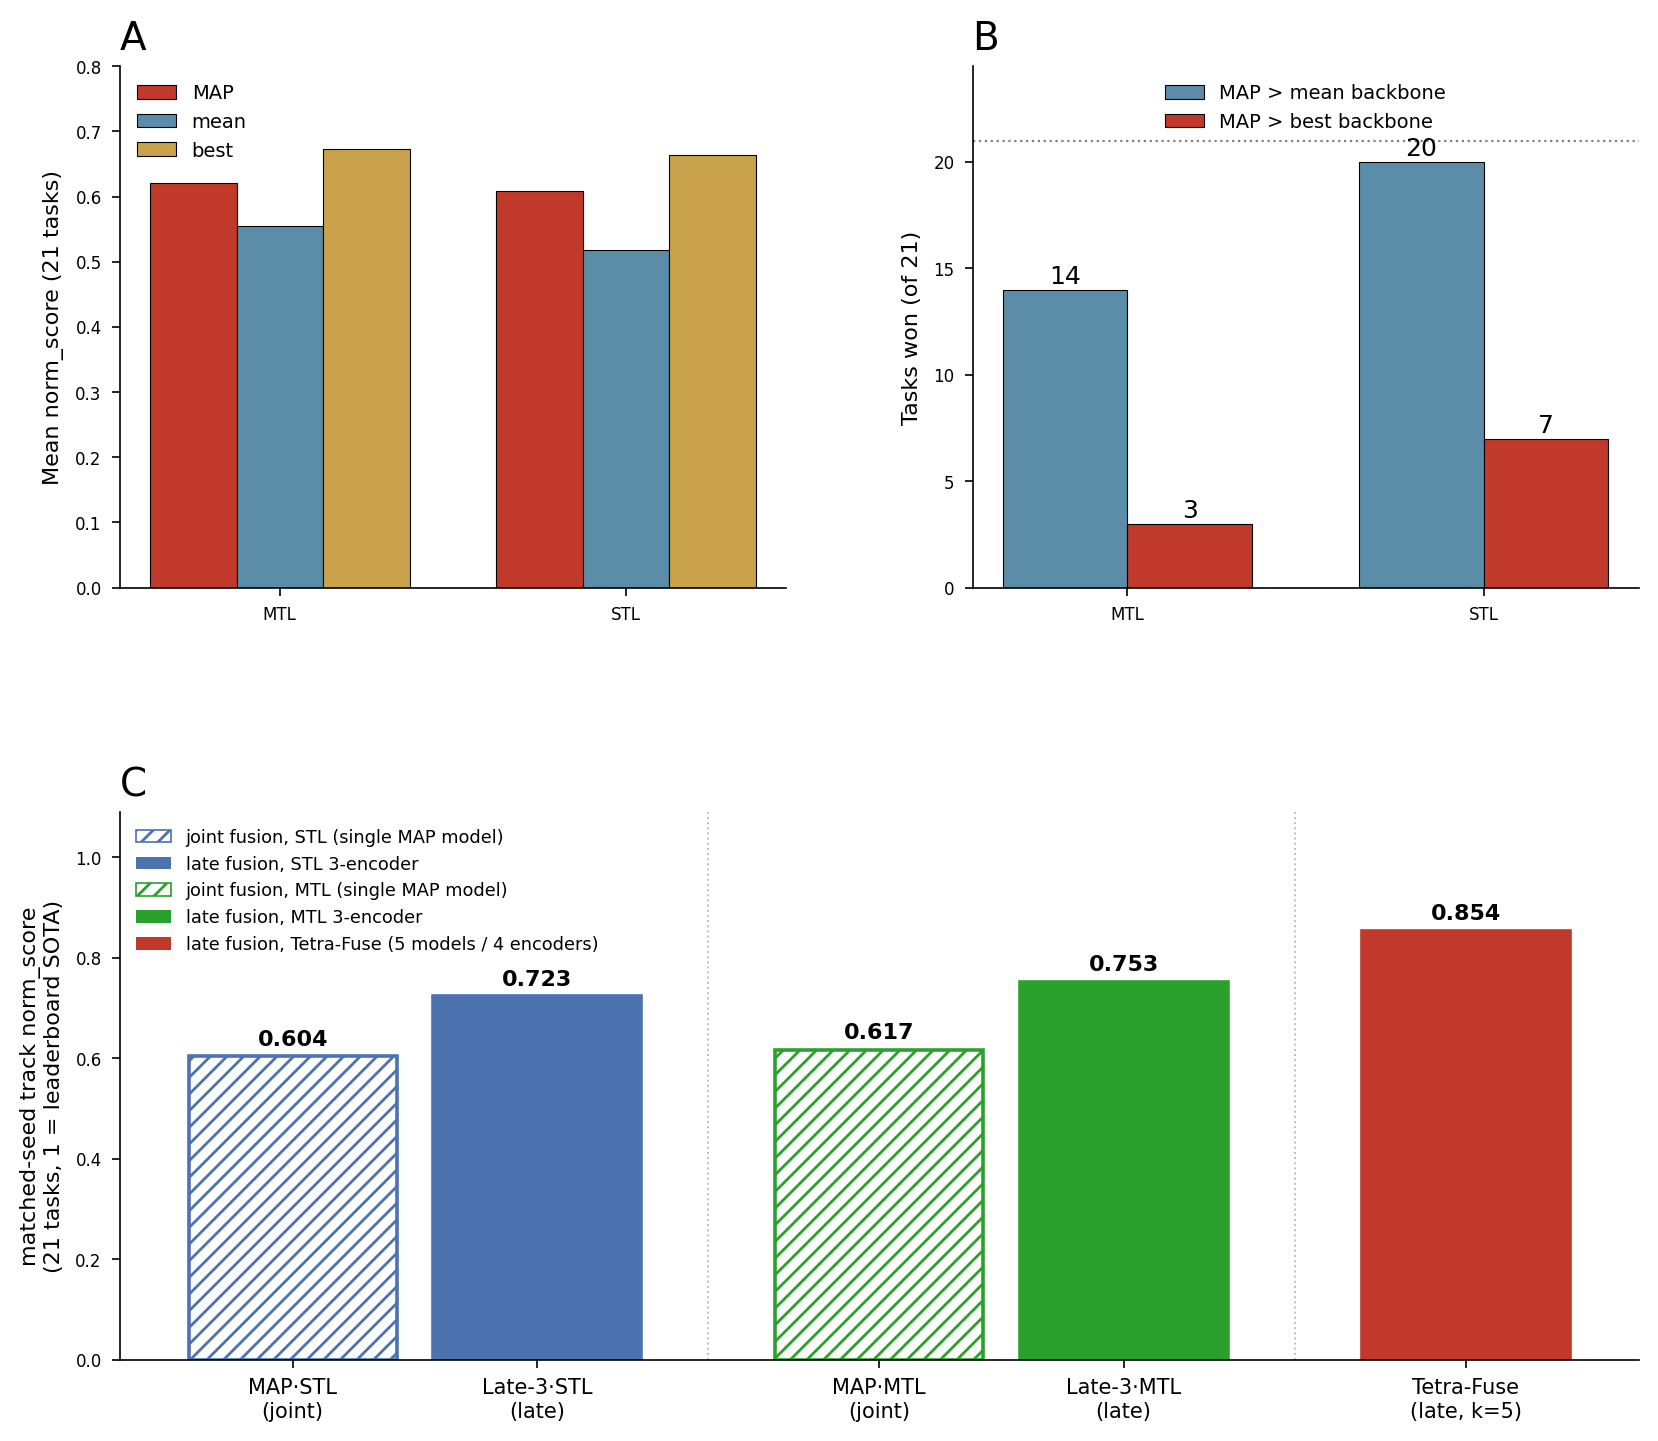

In [2]:
# === figure2.png (representation-level fusion: aggregation + fusion-level comparison) ===
import numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
apply_figure_style(sizes=(8,7,6))

magg = _GT["map_agg"]        # {'mtl':{...}, 'stl':{...}}
RED = "#c0392b"

# ---- panel c data: matched-seed (within-seed) norm, recomputed like Tetra-Fuse ----
# MAP is a single joint-fusion model -> its within norm == solo within norm of {stl,mtl}_map
map_stl = pertask_norm(["stl_map"], True); map_stl = float(np.mean(list(map_stl.values())))
map_mtl = pertask_norm(["mtl_map"], True); map_mtl = float(np.mean(list(map_mtl.values())))
# Late-3 = same 3 encoders as MAP (chemeleon, graphmvp, molformer), prediction-level uniform mean
late3_stl = float(np.mean(list(pertask_norm(["stl_chemeleon","stl_graphmvp","stl_molformer"], True).values())))
late3_mtl = float(np.mean(list(pertask_norm(["mtl_chemeleon","mtl_graphmvp","mtl_molformer"], True).values())))
# Tetra-Fuse matched-seed = final ensemble within norm (== Table 3 within, 0.854)
tetra = float(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]))

fig = plt.figure(figsize=(9.8, 8.4))
gs = GridSpec(2, 2, height_ratios=[1.0, 1.05], hspace=0.42, wspace=0.28)
axA = fig.add_subplot(gs[0,0]); axB = fig.add_subplot(gs[0,1]); axC = fig.add_subplot(gs[1,:])

# (a) mean norm_score for map / mean / max, MTL & STL
groups = ["mtl","stl"]; aggs=["map","mean","best"]
x = np.arange(len(groups)); w=0.25
aggcol={"map":RED,"mean":"#5b8ca8","best":"#c9a24b"}
for i,a in enumerate(aggs):
    axA.bar(x+(i-1)*w, [magg[g][a] for g in groups], w, label=a.upper() if a=="map" else a,
            color=aggcol[a], edgecolor="black", linewidth=0.4)
axA.set_xticks(x); axA.set_xticklabels(["MTL","STL"]); axA.set_ylim(0, 0.8)
axA.set_ylabel("Mean norm_score (21 tasks)")
axA.set_title("A", fontsize=14)
# axA.set_title("a  MAP vs single-backbone reference points", loc="left", fontweight="bold")
axA.legend(frameon=False)

# (b) win-counts: MAP > mean vs MAP > per-task-best, on the RAW-score matched-seed basis
# (panel a keeps norm_score; panel b counts direction-aware raw wins so norm-step ties do not
# distort the count). Per task: MAP raw (within-seed mean) vs the 3 shared backbones' per-seed
# mean / best raw, averaged over seeds (matched-seed track throughout).
labels=["MTL","STL"]
_B3=["chemeleon","graphmvp","molformer"]; _TKb=[t for t in REG if t!="Bioavailability_Ma"]
def _agg_raw(train, task, how):
    met=REG[task]["metric"]; per=[]
    for seed in sorted(PRED[f"{train}_{_B3[0]}"].seed.unique()):
        sc=[]
        for bb in _B3:
            d=PRED[f"{train}_{bb}"]; t=d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
            sc.append(metric(met,t.y_true,t.y_pred))
        per.append(np.mean(sc) if how=="mean" else (min(sc) if met=="mae" else max(sc)))
    return float(np.mean(per))
def _mapwins(train, how):
    n=0
    for t in _TKb:
        met=REG[t]["metric"]; mp=pertask_raw([f"{train}_map"], True)[t]; ref=_agg_raw(train,t,how)
        if (mp<ref) if met=="mae" else (mp>ref): n+=1
    return n
mgt_mean=[_mapwins(g,"mean") for g in groups]
mgt_max =[_mapwins(g,"best") for g in groups]
x2=np.arange(len(labels)); w2=0.35
axB.bar(x2-w2/2, mgt_mean, w2, label="MAP > mean backbone", color="#5b8ca8", edgecolor="black", linewidth=0.4)
axB.bar(x2+w2/2, mgt_max,  w2, label="MAP > best backbone", color=RED, edgecolor="black", linewidth=0.4)
axB.axhline(21, ls=":", color="grey", lw=0.8)
for xx,v in zip(x2-w2/2, mgt_mean): axB.text(xx,v+0.3,str(v),ha="center",fontsize=9)
for xx,v in zip(x2+w2/2, mgt_max):  axB.text(xx,v+0.3,str(v),ha="center",fontsize=9)
axB.set_xticks(x2); axB.set_xticklabels(labels); axB.set_ylim(0,24.5)
axB.set_ylabel("Tasks won (of 21)")
axB.set_title("B", fontsize=14)
# axB.set_title("b  MAP raises the floor, rarely tops the best", loc="left", fontweight="bold")
axB.legend(frameon=False, loc="upper center")

# (c) fusion level, same encoders: joint (MAP, hatched) vs late (uniform-mean, solid), then Tetra-Fuse
STLc="#4c72b0"; MTLc="#2ca02c"; TFc=RED
xc=[0,1, 2.4,3.4, 4.8]
vc=[map_stl, late3_stl, map_mtl, late3_mtl, tetra]
lblc=["MAP\u00b7STL\n(joint)","Late-3\u00b7STL\n(late)","MAP\u00b7MTL\n(joint)","Late-3\u00b7MTL\n(late)","Tetra-Fuse\n(late, k=5)"]
# colour = paradigm (STL blue / MTL green / Tetra red); fill = fusion level (joint hatched, late solid)
specs=[(STLc,"////"),(STLc,None),(MTLc,"////"),(MTLc,None),(TFc,None)]
for xi,vi,(c,h) in zip(xc,vc,specs):
    axC.bar(xi,vi,width=0.85,color=(c if h is None else "white"),edgecolor=c,linewidth=1.3,hatch=h)
    axC.text(xi,vi+0.014,f"{vi:.3f}",ha="center",va="bottom",fontsize=8,fontweight="bold")
axC.axvline(1.7,color="grey",ls=":",lw=0.7,alpha=0.5); axC.axvline(4.1,color="grey",ls=":",lw=0.7,alpha=0.5)
axC.set_xticks(xc); axC.set_xticklabels(lblc,fontsize=7.5)
axC.set_ylabel("matched-seed track norm_score\n(21 tasks, 1 = leaderboard SOTA)",fontsize=8)
axC.set_ylim(0,1.09)
axC.set_title("C", fontsize=14)
# axC.set_title("c  Fusion level alone (same 3 encoders), then ensemble expansion",
#               loc="left",fontweight="bold",fontsize=9.3)
axC.legend(handles=[
    Patch(facecolor="white",edgecolor=STLc,hatch="////",label="joint fusion, STL (single MAP model)"),
    Patch(facecolor=STLc,label="late fusion, STL 3-encoder"),
    Patch(facecolor="white",edgecolor=MTLc,hatch="////",label="joint fusion, MTL (single MAP model)"),
    Patch(facecolor=MTLc,label="late fusion, MTL 3-encoder"),
    Patch(facecolor=TFc,label="late fusion, Tetra-Fuse (5 models / 4 encoders)")],
    loc="upper left",fontsize=6.4,frameon=False)

fig.savefig(os.path.join(OUTDIR,"figure2.png"), dpi=300, bbox_inches="tight")
# plt.close(fig)
print(f"figure2.png written (3-panel). Late-3 within: STL={late3_stl:.4f} MTL={late3_mtl:.4f} | "
      f"MAP within: STL={map_stl:.4f} MTL={map_mtl:.4f} | Tetra={tetra:.4f}")
plt.show()



*Fig. 2 The joint-fusion model (MAP) is benchmarked against single-backbone reference points and against prediction-level late fusion. (a) Mean norm_score over 21 tasks for MAP, for the mean of the three fused backbones' per-task scores, and for the best backbone on each task, under MTL and STL; MAP exceeds the mean backbone but not the per-task best. (b) Per-task win counts on the raw metric (direction handled appropriately): MAP beats the mean of its three backbones on 14/21 tasks (MTL) and 20/21 (STL), but beats the single best backbone on only 3/21 (MTL) and 7/21 (STL). The per-task best is an oracle reference—identifying it requires the test labels—and is reported only as an upper bound. (c) Matched-seed comparison isolating fusion level. Within each learning paradigm, MAP (feature-level, hatched) is compared with a prediction-level uniform mean over exactly the same three backbones (Late-3, solid), holding encoders, paradigm and seeds fixed; late fusion is higher in both (+0.119 STL, +0.136 MTL). Tetra-Fuse (right) additionally draws on a fourth encoder (the from-scratch D-MPNN, excluded from joint fusion, Section 2.3) and combines five models, so its further gain over Late-3·MTL reflects ensemble expansion rather than fusion level alone; MAP·STL is itself one of its five members. Late-3 is composition-matched to MAP rather than validation-selected, and is reported as a post-hoc analysis (Section 2.4). All values are held-out-test, matched-seed. Full per-task values in Supplementary Table S2; heatmap in Supplementary Fig. S1.*

## Fig. S1 Detailed per-task performance of feature-level joint fusion (MAP) compared to base backbones.

The heatmap displays the rank-based normalized scores (norm_score) across all 21 evaluable ADMET tasks. For both Single-Task Learning (STL) and Multi-Task Learning (MTL) paradigms, the performance of the joint-fusion model (MAP) is compared against two references: (1) the Mean score of its three constituent backbones (CheMeleon, MoLFormer, and GraphMVP), and (2) the Best single backbone (Oracle) for each specific task. This figure provides the fine-grained, per-task breakdown corresponding to the aggregated results presented in Fig. 2a.

figureS1.png written (SI heatmap, landscape)


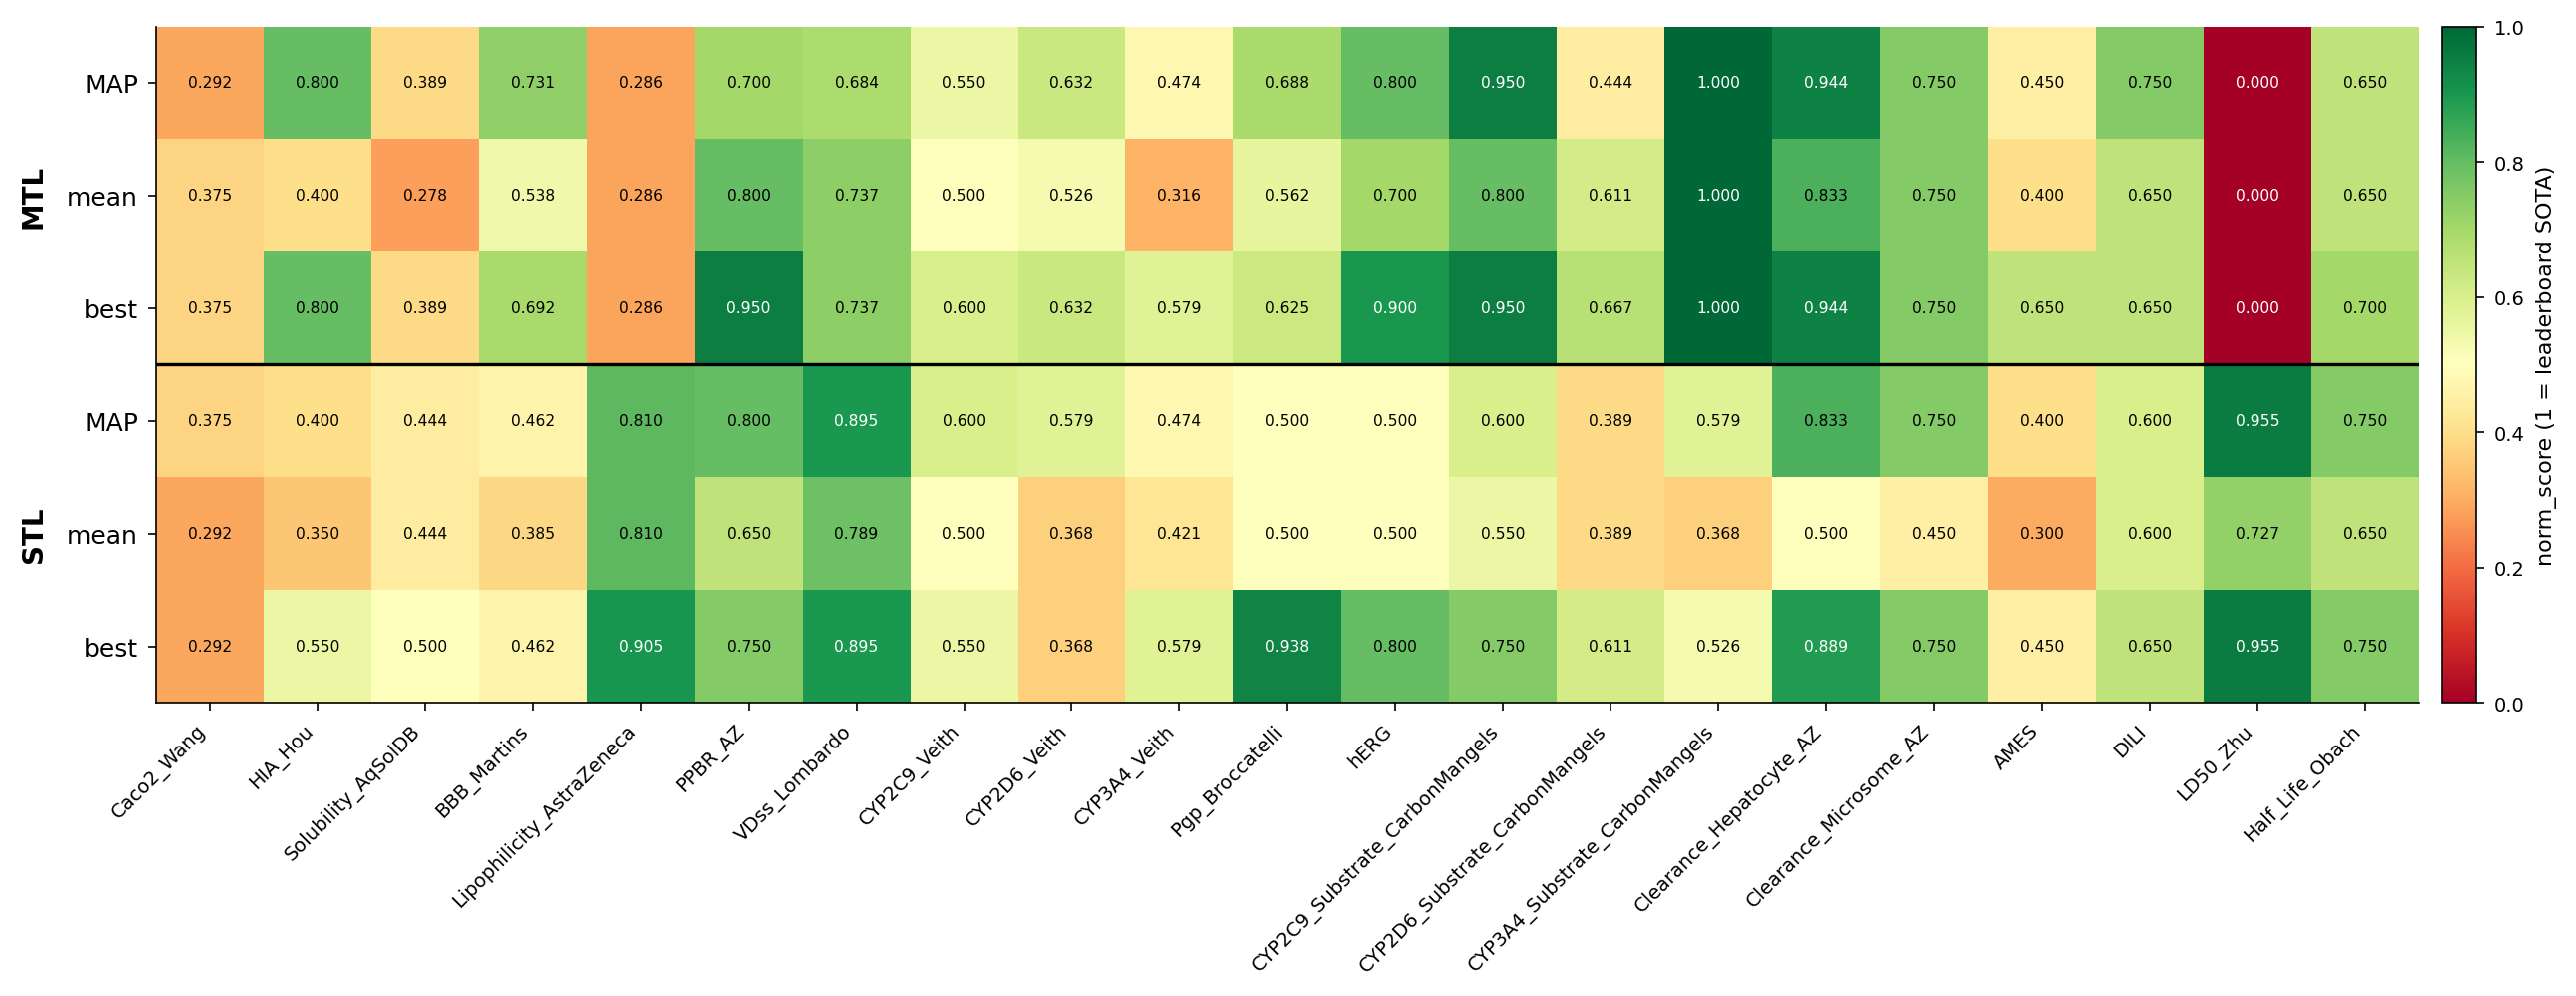

In [3]:
# === figureS1.png (Supplementary: per-task norm_score by aggregation rule) ===
# Landscape orientation: aggregation rules on the y-axis, the 21 tasks along the x-axis
# (transpose of the portrait version; identical values).
import numpy as np, matplotlib.pyplot as plt
apply_figure_style(sizes=(9,8,7))

PT = _PT
t3=PT["t3"]
tasks3=[e["dataset"] for e in t3]
cols3=["mtl_map","mtl_mean","mtl_best","stl_map","stl_mean","stl_best"]
collab=["MAP","mean","best","MAP","mean","best"]
M=np.array([[e[c]["norm"] for c in cols3] for e in t3])  # tasks x 6

fig, axH = plt.subplots(figsize=(15.0, 4.4))
im=axH.imshow(M.T, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)   # 6 x tasks (landscape)
axH.set_yticks(range(6)); axH.set_yticklabels(collab, fontsize=9)
axH.set_xticks(range(len(tasks3))); axH.set_xticklabels(tasks3, rotation=45, ha="right", fontsize=7)
axH.axhline(2.5, color="black", lw=1.2)                            # MTL (rows 0-2) | STL (rows 3-5)
axH.text(-1.5, 1.0, "MTL", va="center", ha="right", fontweight="bold", fontsize=10, rotation=90)
axH.text(-1.5, 4.0, "STL", va="center", ha="right", fontweight="bold", fontsize=10, rotation=90)
for c in range(len(tasks3)):
    for r in range(6):
        v=M[c,r]
        axH.text(c,r,f"{v:.3f}", ha="center", va="center", fontsize=5.6,
                 color="black" if 0.25<v<0.85 else "white")
# axH.set_title("Per-task held-out test norm_score by aggregation rule", loc="center", fontweight="bold", fontsize=10, pad=10)
cbar=fig.colorbar(im, ax=axH, fraction=0.015, pad=0.01)
cbar.set_label("norm_score (1 = leaderboard SOTA)", fontsize=8); cbar.ax.tick_params(labelsize=7)
fig.savefig(os.path.join(OUTDIR,"figureS1.png"), dpi=300, bbox_inches="tight")
print("figureS1.png written (SI heatmap, landscape)")


## Table S2. Detailed per-task performance comparison of fusion strategies and the final Tetra-Fuse ensemble.

This table presents the evaluation metrics across all 21 ADMET tasks under both Single-Task Learning (STL) and Multi-Task Learning (MTL) paradigms. It directly compares the 3-backbone feature-level joint fusion (MAP) against the prediction-level late fusion (Late-3) utilizing the exact same three backbones (CheMeleon, MoLFormer, and GraphMVP). For comprehensive benchmarking, the average performance (Mean) and the optimal single-backbone performance (Best) of the three constituent models on each task are also provided. Additionally, the table includes the performance of the final optimal ensemble, Tetra-Fuse, demonstrating its overall superiority over the 3-backbone baselines. This table provides the precise numerical data corresponding to the aggregated results in Fig. 2.

In [4]:
# --- Table S2: representation-level aggregation (MAP vs latent mean vs latent best),
#     plus prediction-level late-fusion columns for direct fusion-level comparison ---
# Late-3 = the same three encoders as MAP (CheMeleon, GraphMVP, MoLFormer) combined by uniform-mean
#   prediction-level fusion (composition-matched to MAP, NOT validation-selected). Tetra-Fuse = the
#   final k=5 ensemble. All three fusion columns are matched-seed (within=True) per-task raw (norm).
AGG=["mtl_map","mtl_mean","mtl_best","stl_map","stl_mean","stl_best"]
AGG_LAB=["MAP MTL","mean MTL","best MTL","MAP STL","mean STL","best STL"]

_LATE3_STL=["stl_chemeleon","stl_graphmvp","stl_molformer"]
_LATE3_MTL=["mtl_chemeleon","mtl_graphmvp","mtl_molformer"]
_TETRA=list(_GT["final_ensemble"])   # k=5
_fuse_specs=[("Late-3 STL",_LATE3_STL),("Late-3 MTL",_LATE3_MTL),("Tetra-Fuse",_TETRA)]
# per-task matched-seed raw + norm for each fusion (computed once here from source predictions)
_fuse_raw ={lab: pertask_raw(ms, True)  for lab,ms in _fuse_specs}
_fuse_norm={lab: pertask_norm(ms, True) for lab,ms in _fuse_specs}
def _fcell(lab, task):
    return f"{_fuse_raw[lab][task]:.3f} ({_fuse_norm[lab][task]:.3f})"

rows=[]
for e in _PT["t3"]:
    tk=e["dataset"]
    r=[e["group"], tk, e["metric"]] + [cell(e[a]) for a in AGG] + [_fcell(lab, tk) for lab,_ in _fuse_specs]
    rows.append(r)
cols=["Group","Dataset","Metric"]+AGG_LAB+["Late-3 STL","Late-3 MTL","Tetra-Fuse"]
S2=pd.DataFrame(rows, columns=cols)
S2 = S2[['Group', 'Dataset', 'Metric',
 'MAP MTL', 'mean MTL', 'best MTL', 'Late-3 MTL', 
 'MAP STL', 'mean STL', 'best STL', 'Late-3 STL', 'Tetra-Fuse']]
register("tableS2_representation_aggregation", S2)
assert S2.iloc[0]["Dataset"]=="Caco2_Wang" and S2.iloc[0]["MAP MTL"]=="0.443 (0.292)", S2.iloc[0].to_dict()
assert len(S2)==21 and {"Late-3 STL","Late-3 MTL","Tetra-Fuse"}.issubset(S2.columns)
print("S2 OK", S2.shape); S2.head(3)


S2 OK (21, 12)


,Group,Dataset,Metric,MAP MTL,mean MTL,best MTL,Late-3 MTL,MAP STL,mean STL,best STL,Late-3 STL,Tetra-Fuse
0,oral_uptake,Caco2_Wang,mae,0.443 (0.292),0.384 (0.375),0.36 (0.375),0.332 (0.542),0.37 (0.375),0.437 (0.292),0.419 (0.292),0.323 (0.625),0.308 (0.667)
1,oral_uptake,HIA_Hou,auroc,0.987 (0.800),0.966 (0.400),0.988 (0.800),0.989 (0.900),0.97 (0.400),0.963 (0.350),0.977 (0.550),0.978 (0.550),0.992 (0.950)
2,oral_uptake,Solubility_AqSolDB,mae,0.931 (0.389),0.95 (0.278),0.916 (0.389),0.872 (0.444),0.844 (0.444),0.864 (0.444),0.828 (0.500),0.787 (0.778),0.775 (0.889)


## Fig. 3 Prediction-level late fusion, ensemble-size sweep.

*Figure 3. Prediction-level late fusion, ensemble-size sweep. (a) Validation norm_score (mean of the top-20 combinations at each size) versus ensemble size k, for the matched-seed and seed-averaged tracks; performance saturates at k = 5 (dashed line). (b) Marginal validation gain from adding the k-th model, shown separately for each track, with the combined (matched + seed-averaged) gain annotated. The combined gain falls from +0.0104 at k = 4→5 to +0.0029 at k = 5→6 — crossing below the ε = 0.01 saturation threshold — and is negative for k = 7–9 (a marginal +0.005 reappears only at k = 10), so k = 5 is taken as the elbow. The corresponding numerical values are provided in Supplementary Table S3.*

saved figure3.png


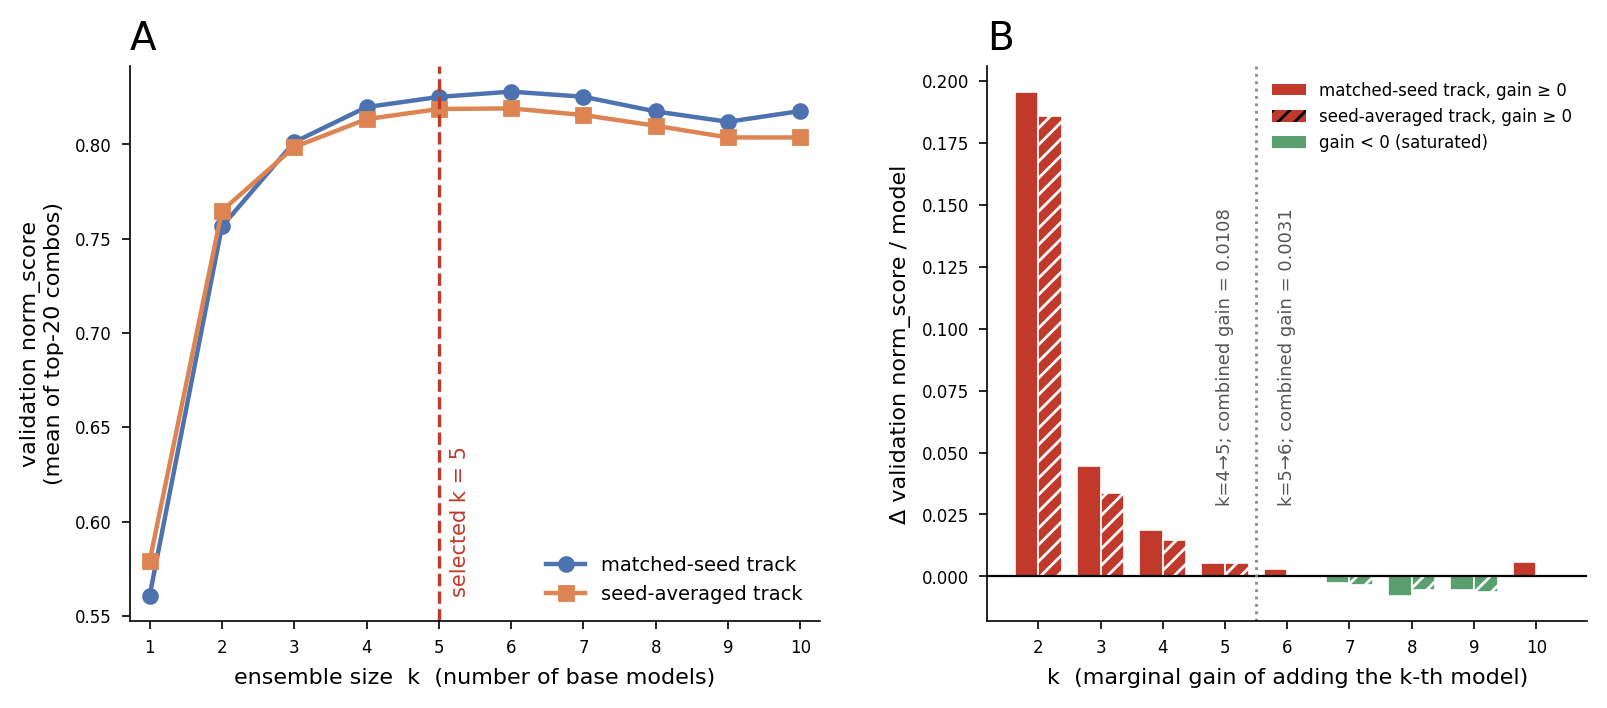

In [5]:
# === figure3.png ===
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# skill:figure-style kernel.py (auto-injected on skill load)
META_GREY = "#888888"




apply_figure_style(sizes=(8, 7, 6))

GT = _GT

ks = GT["ksweep"]
kk = [r[0] for r in ks]
w_top = [r[1] for r in ks]; w_marg = [r[2] for r in ks]
c_top = [r[3] for r in ks]; c_marg = [r[4] for r in ks]

plt.close('all')
fig = plt.figure(figsize=(9.4,3.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], wspace=0.26)
axL = fig.add_subplot(gs[0, 0]); axR = fig.add_subplot(gs[0, 1])
axL.plot(kk, w_top, "-o", color="#4c72b0", label="matched-seed track", markersize=5, lw=1.6)
axL.plot(kk, c_top, "-s", color="#dd8452", label="seed-averaged track", markersize=5, lw=1.6)
axL.axvline(5, color="#c0392b", ls="--", lw=1.2)
axL.text(5.15, 0.56, "selected k = 5", color="#c0392b", fontsize=7.5, rotation=90, va="bottom")
axL.set_xlabel("ensemble size  k  (number of base models)")
axL.set_ylabel("validation norm_score\n(mean of top-20 combos)")
axL.set_xticks(kk)
axL.set_title("A", fontsize=14)
# axL.set_title("a  Validation performance saturates at k=5", loc="left", fontweight="bold", fontsize=9)
axL.legend(fontsize=7, frameon=False, loc="lower right"); axL.margins(x=0.03)

# Panel B sign-based, separate within & cross bars
xb = np.array(kk[1:])
gw = w_marg[1:]; gc = c_marg[1:]
bw = 0.38
def sc(g): return "#c0392b" if g >= 0 else "#5aa06f"
axR.bar(xb - bw/2, gw, width=bw, color=[sc(g) for g in gw], edgecolor="white")
axR.bar(xb + bw/2, gc, width=bw, color=[sc(g) for g in gc], edgecolor="white", hatch="////")
axR.axhline(0, color="black", lw=0.8)
axR.axvline(5.5, color="#888", ls=":", lw=1)
axR.text(5, 0.03, f"k=4→5; combined gain = {[r[2] for r in ks][4] + [r[4] for r in ks][4]}", fontsize=6.5, rotation=90, color="#555", ha="center")
axR.text(6, 0.03, f"k=5→6; combined gain = {[r[2] for r in ks][5] + [r[4] for r in ks][5]}", fontsize=6.5, rotation=90, color="#555", ha="center")
axR.set_xlabel("k  (marginal gain of adding the k-th model)")
axR.set_ylabel("Δ validation norm_score / model")
axR.set_xticks(xb)
axR.set_title("B", fontsize=14)
# axR.set_title("b  Diminishing returns beyond k=5", loc="left", fontweight="bold", fontsize=9)
axR.legend(handles=[Patch(facecolor="#c0392b", label="matched-seed track, gain ≥ 0"),
                    Patch(facecolor="#c0392b", hatch="////", label="seed-averaged track, gain ≥ 0"),
                    Patch(facecolor="#5aa06f", label="gain < 0 (saturated)")],
           fontsize=6, frameon=False, loc="upper right")
fig.savefig(os.path.join(OUTDIR,"figure3.png"), dpi=300, bbox_inches="tight")
print("saved figure3.png")

## Table S3. Validation-based combined scores and marginal gains for ensemble size optimization.

Detailed numerical data corresponding to the ensemble size analysis in Fig. 3a,b. The table tracks matched-seed, cross-seed, and combined scores on the validation set for ensemble sizes $k = 1$ through 10. The combined gain column highlights the plateau effect, showing the exact point where adding a sixth member yields an increment below the $\epsilon = 0.01$ threshold, leading to the selection of the optimal $k=5$ ensemble.

In [6]:
# --- Table S3: ensemble-size sweep (top-20 mean validation norm_score, both tracks + combined) ---
# ksweep rows: [k, within_top20mean, within_marg, cross_top20mean, cross_marg]
# Combined = matched-seed + seed-averaged (sum); the combined marginal is the basis on which
# Figure 3b defines the k=5 elbow (k4->5 above eps=0.01, k5->6 below).
ks=_GT["ksweep"]
def fmt(x): return "\u2014" if x is None else f"{x:+.4f}"
rows=[]
for k, wtop, wmarg, ctop, cmarg in ks:
    comb_top = wtop + ctop
    comb_marg = None if (wmarg is None or cmarg is None) else (wmarg + cmarg)
    rows.append([k, f"{wtop:.4f}", fmt(wmarg), f"{ctop:.4f}", fmt(cmarg),
                 f"{comb_top:.4f}", fmt(comb_marg)])
S3=pd.DataFrame(rows, columns=["k","Matched-seed top-20 mean","Matched-seed marginal",
                               "Seed-averaged top-20 mean","Seed-averaged marginal",
                               "Combined top-20 mean","Combined marginal"])
register("tableS3_ksweep", S3)
assert S3.iloc[0]["Matched-seed top-20 mean"]=="0.5607", S3.iloc[0].to_dict()
# combined-marginal elbow check: k4->5 above eps=0.01, k5->6 below (manuscript Figure 3 basis)
comb_k5 = (ks[4][2]+ks[4][4])   # within_marg + cross_marg at k=5
comb_k6 = (ks[5][2]+ks[5][4])
assert comb_k5 > 0.01 and comb_k6 < 0.01, (comb_k5, comb_k6)
# Combined columns consistency: combined top-20 = matched + seed-averaged
assert abs(float(S3.iloc[4]["Combined top-20 mean"]) - (ks[4][1]+ks[4][3])) < 1e-9
assert S3.iloc[4]["Combined marginal"]==fmt(comb_k5) and S3.iloc[5]["Combined marginal"]==fmt(comb_k6)
assert len(S3)==10 and S3.shape[1]==7
print("S3 OK", S3.shape, "| k4->5 combined marg", round(comb_k5,4), "k5->6", round(comb_k6,4)); S3


S3 OK (10, 7) | k4->5 combined marg 0.0108 k5->6 0.0031


,k,Matched-seed top-20 mean,Matched-seed marginal,Seed-averaged top-20 mean,Seed-averaged marginal,Combined top-20 mean,Combined marginal
0,1,0.5607,—,0.5790,—,1.1397,—
1,2,0.7565,+0.1958,0.7648,+0.1858,1.5213,+0.3816
2,3,0.8012,+0.0447,0.7986,+0.0338,1.5998,+0.0785
3,4,0.8198,+0.0186,0.8134,+0.0148,1.6332,+0.0334
4,5,0.8252,+0.0054,0.8188,+0.0054,1.6440,+0.0108
5,6,0.8280,+0.0028,0.8191,+0.0003,1.6471,+0.0031
6,7,0.8253,-0.0027,0.8156,-0.0035,1.6409,-0.0062
7,8,0.8175,-0.0078,0.8099,-0.0057,1.6274,-0.0135
8,9,0.8120,-0.0055,0.8037,-0.0062,1.6157,-0.0117
9,10,0.8177,+0.0057,0.8037,+0.0000,1.6214,+0.0057


## Fig. S2 Comprehensive per-task performance heatmap and win counts across all fusion and aggregation rules.

*This figure provides a visual breakdown of the performance metrics across the 21 ADMET tasks for all evaluated aggregation rules, including feature-level joint fusion (MAP), theoretical baselines (mean and best single-backbone), prediction-level late fusion (Late-3), and the final optimal ensemble (Tetra-Fuse) under both MTL and STL paradigms. The top panel shows a heatmap of the rank-normalized scores, with stars ($\star$) indicating the raw-score winner for each task. The bottom panels summarize the mean normalized score and the total number of tasks won by each rule. Notably, Tetra-Fuse achieves the highest mean score (0.854) and dominates the per-task win counts (11 out of 21 tasks), visually demonstrating its overarching superiority over all other baselines.*

figureS2.png written (landscape) | Tetra mean 0.854 | # tasks best {'MAP MTL': 0, 'mean MTL': 0, 'best MTL': 2, 'Late-3 MTL': 5, 'MAP STL': 1, 'mean STL': 0, 'best STL': 1, 'Late-3 STL': 1, 'Tetra-Fuse': 11}


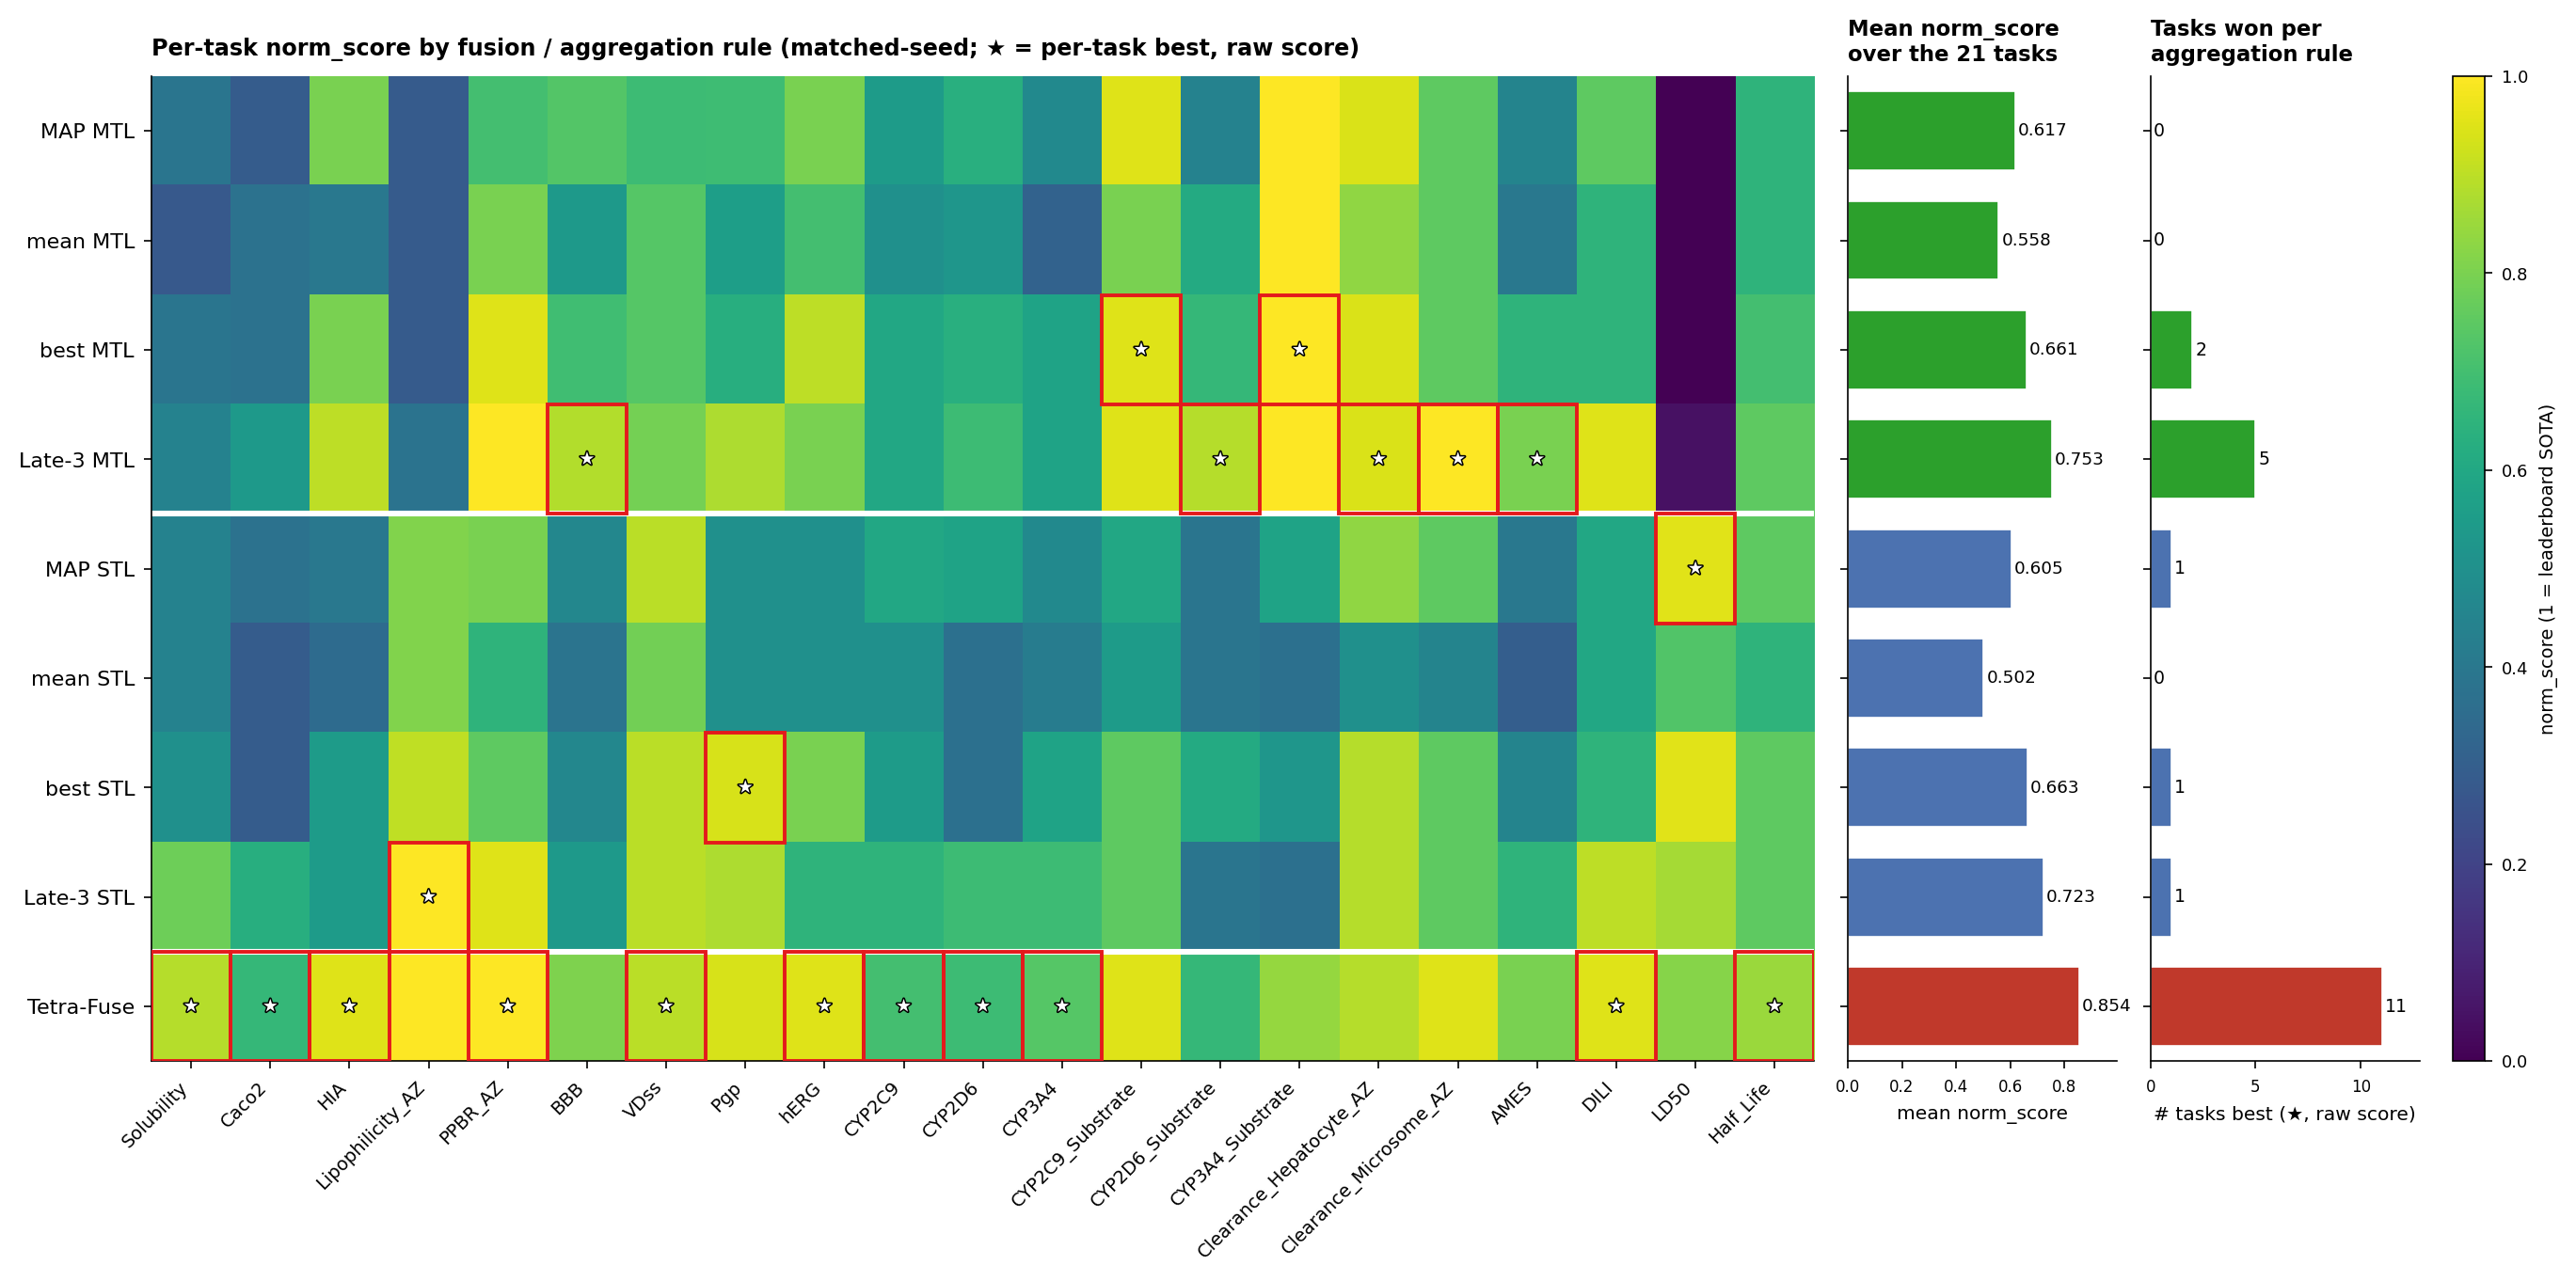

In [7]:
# === figureS2.png (Supplementary: per-task aggregation comparison, Fig.1a style) ===
# Same visual grammar as Figure 1a but for the representation-level aggregation columns of
# Table S2: a task x aggregation heatmap of matched-seed norm_score, with the per-task best
# column marked by a red box + star (chosen on the underlying RAW metric, direction-aware,
# exactly as in Fig.1a so ties do not spuriously multiply). Two summary bars beneath the
# heatmap give, for each aggregation, its mean norm_score over the 21 tasks and the number of
# tasks on which it is the per-task raw-score winner ("# tasks best"). Columns follow Table S2
# order (MTL block, then STL block, then Tetra-Fuse).
import numpy as np, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
apply_figure_style(sizes=(8,7,6))

# --- columns (same set/order as Table S2) ---
_S3_SPECS=[("MAP MTL",["mtl_map"]),("mean MTL","AGG:mtl_mean"),("best MTL","AGG:mtl_best"),
           ("Late-3 MTL",["mtl_chemeleon","mtl_graphmvp","mtl_molformer"]),
           ("MAP STL",["stl_map"]),("mean STL","AGG:stl_mean"),("best STL","AGG:stl_best"),
           ("Late-3 STL",["stl_chemeleon","stl_graphmvp","stl_molformer"]),
           ("Tetra-Fuse",list(_GT["final_ensemble"]))]
_S3_LABELS=[s[0] for s in _S3_SPECS]
_t3={e["dataset"]:e for e in _PT["t3"]}                       # MAP/mean/best per-task {raw,norm}
_task_order=[t for g in _FIG1["groups"].values() for t in g]  # mechanism-group task order (21)

def _col_norm_raw(spec):
    """Return {task:(raw,norm)} for one aggregation column."""
    kind=spec[1]
    if isinstance(kind,str) and kind.startswith("AGG:"):        # mtl_mean/mtl_best/... from _PT['t3']
        key=kind.split(":")[1]
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    if spec[0] in ("MAP MTL","MAP STL"):                         # single MAP model from _PT['t3']
        key="mtl_map" if spec[0]=="MAP MTL" else "stl_map"
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    ms=kind                                                      # Late-3 / Tetra: uniform-mean fusion
    raw=pertask_raw(ms,True); nrm=pertask_norm(ms,True)
    return {t:(raw[t],nrm[t]) for t in _task_order}

_cols_data=[_col_norm_raw(s) for s in _S3_SPECS]
Nmat=np.array([[_cols_data[j][t][1] for j in range(len(_S3_SPECS))] for t in _task_order])  # norm, tasks x cols
Rmat=np.array([[_cols_data[j][t][0] for j in range(len(_S3_SPECS))] for t in _task_order])  # raw
n_t,n_c=Nmat.shape
mean_norm=Nmat.mean(axis=0)                                     # per-column mean norm

# per-task best column by RAW (direction-aware; single winner, matches Fig.1a)
best_mask=np.zeros_like(Nmat,dtype=bool)
for i,t in enumerate(_task_order):
    met=REG[t]["metric"]; vals=Rmat[i,:]
    tgt=vals.min() if met=="mae" else vals.max()
    best_mask[i, np.abs(vals-tgt)<=1e-9]=True
ntask_best=best_mask.sum(axis=0)                               # per-column # tasks best (sum=21)

SHORT={"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity_AZ",
 "PPBR_AZ":"PPBR_AZ","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Substrate",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Substrate","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Substrate",
 "Clearance_Hepatocyte_AZ":"Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ":"Clearance_Microsome_AZ",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
_bcol=["#2ca02c","#2ca02c","#2ca02c","#2ca02c","#4c72b0","#4c72b0","#4c72b0","#4c72b0","#c0392b"]

plt.close('all')
# landscape: tasks along x, aggregation columns along y; two summary bars to the right share the y-axis
fig=plt.figure(figsize=(16.0,6.8))
outer=GridSpec(1,4,width_ratios=[n_t,3.4,3.4,0.4],wspace=0.06)
axH=fig.add_subplot(outer[0])
axM=fig.add_subplot(outer[1], sharey=axH)   # mean norm_score (horizontal)
axN=fig.add_subplot(outer[2], sharey=axH)   # # tasks best (horizontal)
axC=fig.add_subplot(outer[3])               # colorbar (vertical, far right)
star_pe=[pe.withStroke(linewidth=1.1,foreground="black")]

im=axH.imshow(Nmat.T,aspect="auto",cmap="viridis",vmin=0,vmax=1)   # cols x tasks
axH.set_yticks(range(n_c)); axH.set_yticklabels(_S3_LABELS,fontsize=8)
axH.set_xticks(range(n_t)); axH.set_xticklabels([SHORT[t] for t in _task_order],rotation=45,ha="right",fontsize=7)
for i in range(n_t):
    for j in range(n_c):
        if best_mask[i,j]:
            axH.add_patch(Rectangle((i-0.5,j-0.5),1,1,fill=False,edgecolor="#e41a1c",lw=1.4,zorder=4))
            axH.text(i,j,"\u2605",ha="center",va="center",color="white",fontsize=6.8,zorder=5,path_effects=star_pe)
axH.axhline(3.5,color="white",lw=2.2)   # MTL | STL block divider (4 MTL rows, 4 STL rows)
axH.axhline(7.5,color="white",lw=2.2)   # STL | Tetra-Fuse divider
cb=fig.colorbar(im,cax=axC); cb.set_label("norm_score (1 = leaderboard SOTA)",fontsize=7); cb.ax.tick_params(labelsize=6.5)
axH.set_title("Per-task norm_score by fusion / aggregation rule (matched-seed; \u2605 = per-task best, raw score)",
              loc="left",fontweight="bold",fontsize=8.6,pad=8)

y=np.arange(n_c)
axM.barh(y,mean_norm,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,mean_norm): axM.text(v+0.01,yi,f"{v:.3f}",va="center",ha="left",fontsize=6.6)
axM.set_xlim(0,max(mean_norm)+0.14); axM.tick_params(labelleft=False)
axM.set_xlabel("mean norm_score",fontsize=7.3)
axM.set_title("Mean norm_score\nover the 21 tasks",loc="left",fontweight="bold",fontsize=8.2)
axN.barh(y,ntask_best,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,ntask_best): axN.text(v+0.15,yi,str(int(v)),va="center",ha="left",fontsize=6.8)
axN.set_xlim(0,ntask_best.max()+1.8); axN.tick_params(labelleft=False)
axN.set_xlabel("# tasks best (\u2605, raw score)",fontsize=7.3)
axN.set_title("Tasks won per\naggregation rule",loc="left",fontweight="bold",fontsize=8.2)

fig.savefig(os.path.join(OUTDIR,"figureS2.png"),dpi=300,bbox_inches="tight")
assert abs(mean_norm[-1]-0.854)<0.01, mean_norm[-1]
assert int(ntask_best.sum())==21, int(ntask_best.sum())
print("figureS2.png written (landscape) | Tetra mean", round(float(mean_norm[-1]),3),
      "| # tasks best", dict(zip(_S3_LABELS,[int(v) for v in ntask_best])))
plt.show()


## Fig. S3 Per-task performance heatmap and win counts comparing Tetra-Fuse against feature-level joint fusion and single-backbone baselines.

*This figure presents a focused comparison by excluding the 3-backbone late fusion (Late-3) baselines from the analysis shown in Fig. S2. This allows for a direct evaluation of the final Tetra-Fuse ensemble against the feature-level joint fusion (MAP) and the single-backbone baselines (mean and oracle best). The heatmap displays the rank-normalized scores (stars denote raw-score winners), while the bottom panels show the overall mean scores and task win counts. In this restricted setting, Tetra-Fuse's dominance is even more pronounced, securing first place in 14 out of the 21 tasks, decisively outperforming both the joint fusion approach and the oracle best individual backbones.*

figureS3.png written (landscape) | cols ['MAP MTL', 'mean MTL', 'best MTL', 'MAP STL', 'mean STL', 'best STL', 'Tetra-Fuse'] | Tetra mean 0.854 | # tasks best {'MAP MTL': 1, 'mean MTL': 0, 'best MTL': 3, 'MAP STL': 1, 'mean STL': 0, 'best STL': 1, 'Tetra-Fuse': 15}


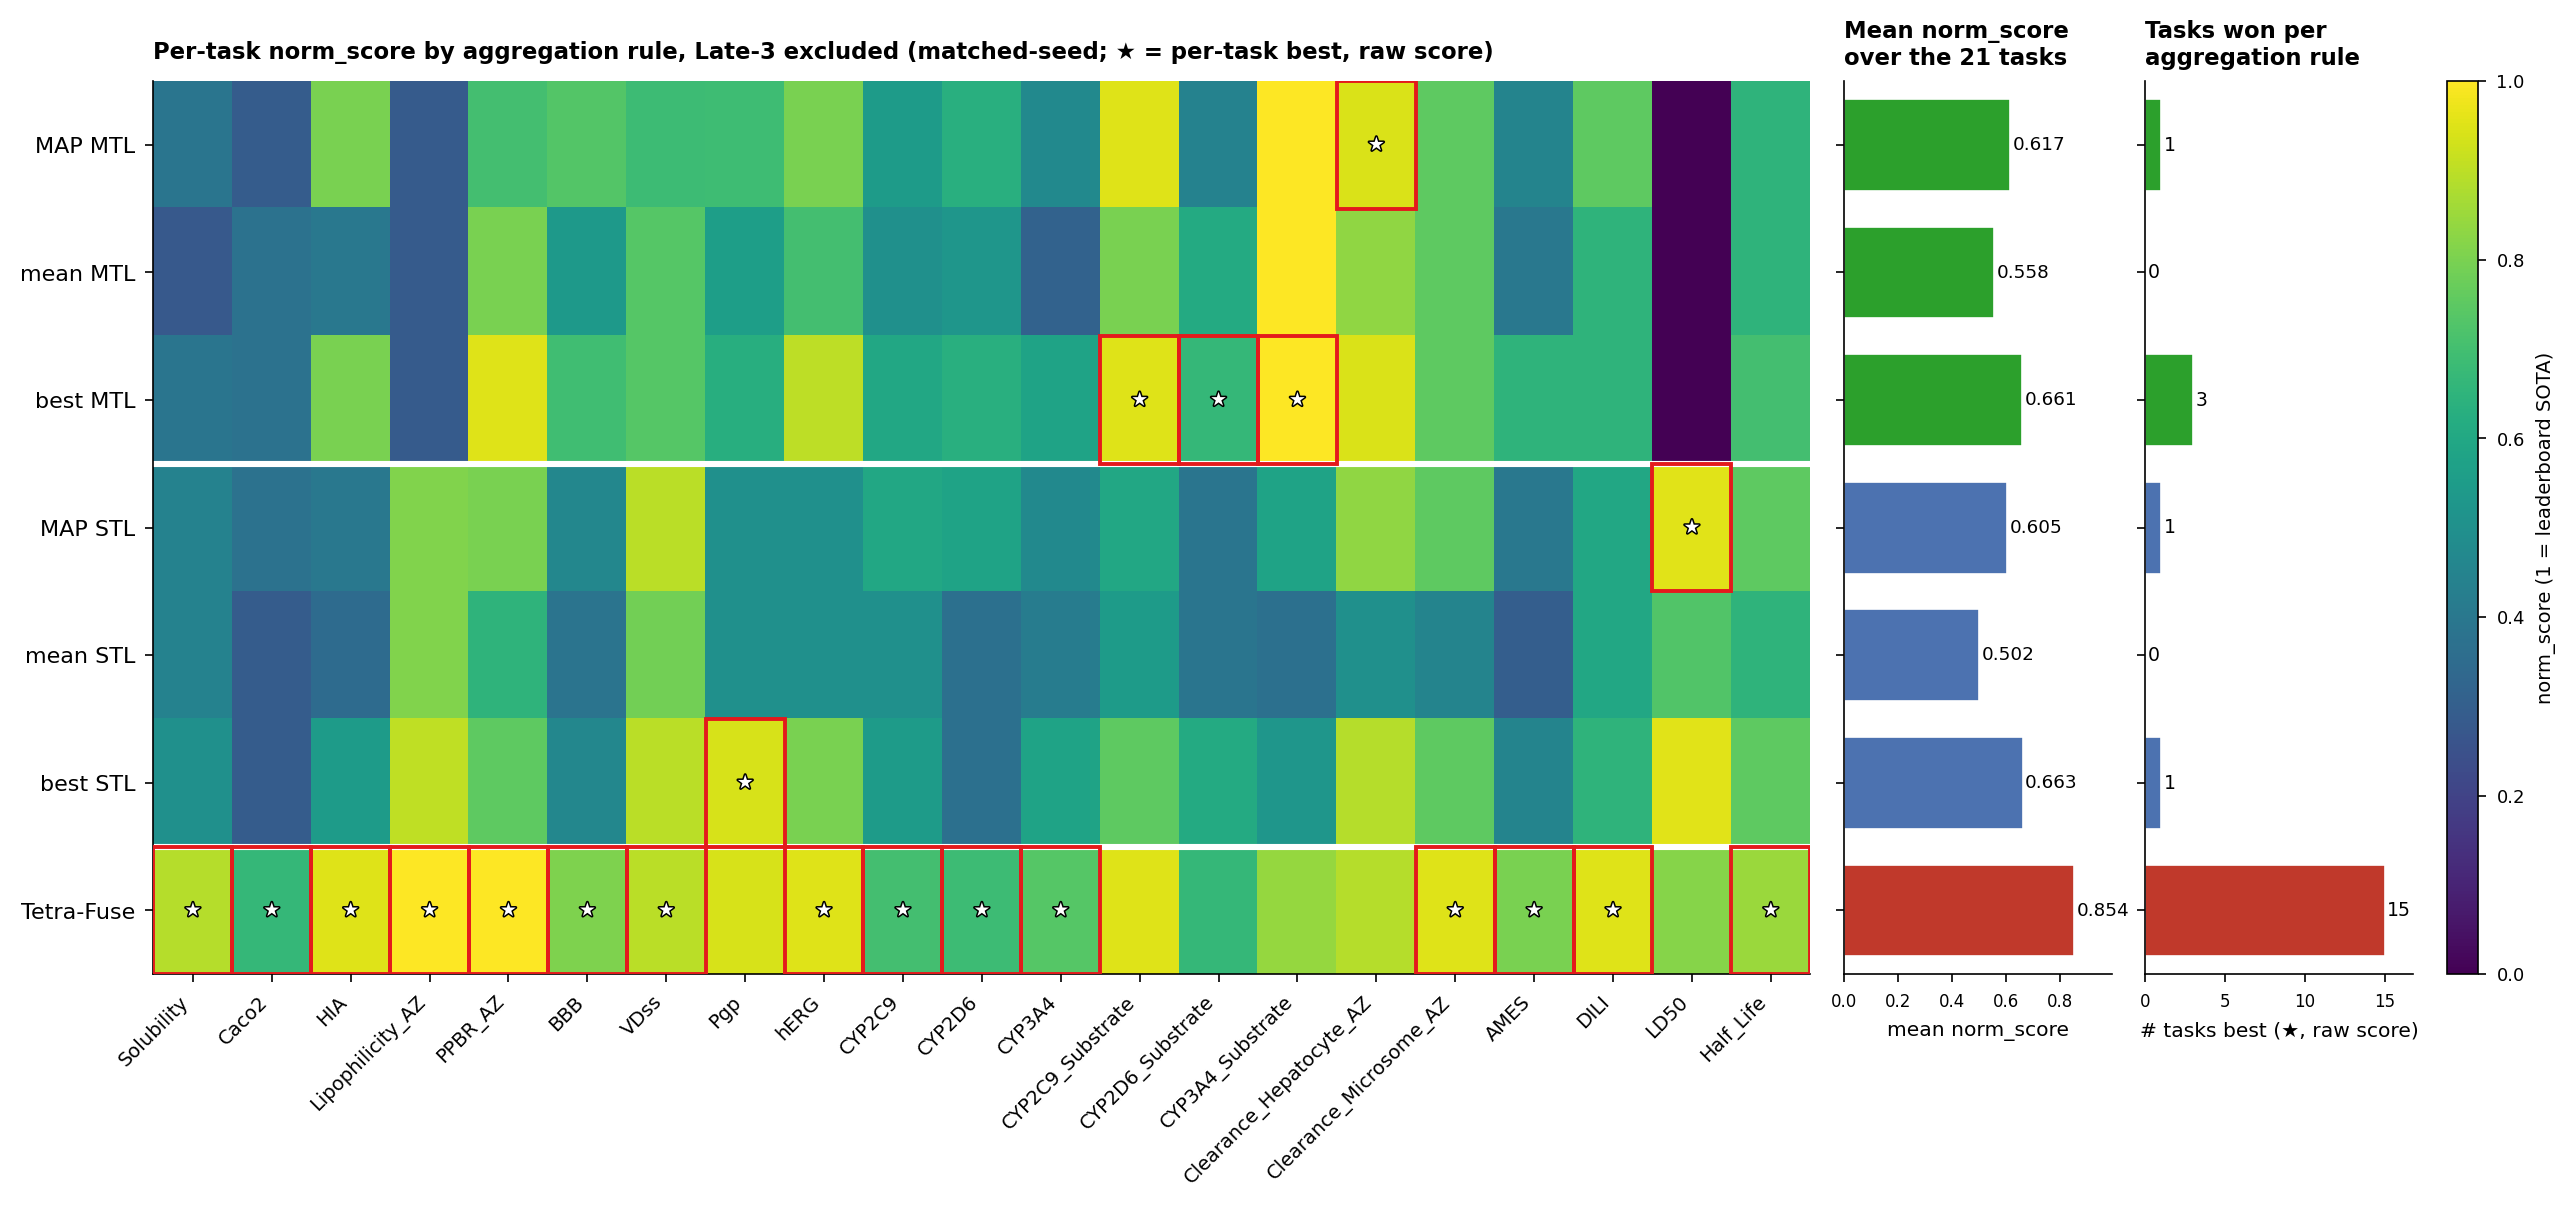

In [8]:
# === figureS3.png (Supplementary: aggregation comparison WITHOUT Late-3, Fig.1a style) ===
# Identical to Figure S2 but with the prediction-level Late-3 columns removed, so only the
# representation-level aggregation rules remain (MAP / naive latent mean / latent best, under
# MTL and STL) plus the final Tetra-Fuse ensemble. This isolates the joint-fusion (MAP) vs
# naive-aggregation contrast without the composition-matched late-fusion column.
import numpy as np, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
apply_figure_style(sizes=(8,7,6))

# --- columns: Table S2 aggregation set MINUS Late-3 (MTL block, STL block, then Tetra-Fuse) ---
_S5_SPECS=[("MAP MTL",["mtl_map"]),("mean MTL","AGG:mtl_mean"),("best MTL","AGG:mtl_best"),
           ("MAP STL",["stl_map"]),("mean STL","AGG:stl_mean"),("best STL","AGG:stl_best"),
           ("Tetra-Fuse",list(_GT["final_ensemble"]))]
_S5_LABELS=[s[0] for s in _S5_SPECS]
_t3={e["dataset"]:e for e in _PT["t3"]}                       # MAP/mean/best per-task {raw,norm}
_task_order=[t for g in _FIG1["groups"].values() for t in g]  # mechanism-group task order (21)

def _col_norm_raw(spec):
    """Return {task:(raw,norm)} for one aggregation column."""
    kind=spec[1]
    if isinstance(kind,str) and kind.startswith("AGG:"):        # mtl_mean/mtl_best/... from _PT['t3']
        key=kind.split(":")[1]
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    if spec[0] in ("MAP MTL","MAP STL"):                         # single MAP model from _PT['t3']
        key="mtl_map" if spec[0]=="MAP MTL" else "stl_map"
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    ms=kind                                                      # Tetra: uniform-mean fusion
    raw=pertask_raw(ms,True); nrm=pertask_norm(ms,True)
    return {t:(raw[t],nrm[t]) for t in _task_order}

_cols_data=[_col_norm_raw(s) for s in _S5_SPECS]
Nmat=np.array([[_cols_data[j][t][1] for j in range(len(_S5_SPECS))] for t in _task_order])  # norm, tasks x cols
Rmat=np.array([[_cols_data[j][t][0] for j in range(len(_S5_SPECS))] for t in _task_order])  # raw
n_t,n_c=Nmat.shape
mean_norm=Nmat.mean(axis=0)

# per-task best column by RAW (direction-aware; single winner, matches Fig.1a)
best_mask=np.zeros_like(Nmat,dtype=bool)
for i,t in enumerate(_task_order):
    met=REG[t]["metric"]; vals=Rmat[i,:]
    tgt=vals.min() if met=="mae" else vals.max()
    best_mask[i, np.abs(vals-tgt)<=1e-9]=True
ntask_best=best_mask.sum(axis=0)                               # per-column # tasks best (sum=21)

SHORT={"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity_AZ",
 "PPBR_AZ":"PPBR_AZ","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Substrate",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Substrate","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Substrate",
 "Clearance_Hepatocyte_AZ":"Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ":"Clearance_Microsome_AZ",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
# 3 MTL (green) + 3 STL (blue) + Tetra (red)
_bcol=["#2ca02c","#2ca02c","#2ca02c","#4c72b0","#4c72b0","#4c72b0","#c0392b"]

plt.close('all')
# landscape: tasks along x, aggregation columns along y; two summary bars to the right share the y-axis
fig=plt.figure(figsize=(15.0,5.8))
outer=GridSpec(1,4,width_ratios=[n_t,3.4,3.4,0.4],wspace=0.06)
axH=fig.add_subplot(outer[0])
axM=fig.add_subplot(outer[1], sharey=axH)
axN=fig.add_subplot(outer[2], sharey=axH)
axC=fig.add_subplot(outer[3])
star_pe=[pe.withStroke(linewidth=1.1,foreground="black")]

im=axH.imshow(Nmat.T,aspect="auto",cmap="viridis",vmin=0,vmax=1)   # cols x tasks
axH.set_yticks(range(n_c)); axH.set_yticklabels(_S5_LABELS,fontsize=8)
axH.set_xticks(range(n_t)); axH.set_xticklabels([SHORT[t] for t in _task_order],rotation=45,ha="right",fontsize=7)
for i in range(n_t):
    for j in range(n_c):
        if best_mask[i,j]:
            axH.add_patch(Rectangle((i-0.5,j-0.5),1,1,fill=False,edgecolor="#e41a1c",lw=1.4,zorder=4))
            axH.text(i,j,"\u2605",ha="center",va="center",color="white",fontsize=6.8,zorder=5,path_effects=star_pe)
axH.axhline(2.5,color="white",lw=2.2)   # MTL (3 rows) | STL (3 rows) divider
axH.axhline(5.5,color="white",lw=2.2)   # STL | Tetra-Fuse divider
cb=fig.colorbar(im,cax=axC); cb.set_label("norm_score (1 = leaderboard SOTA)",fontsize=7); cb.ax.tick_params(labelsize=6.5)
axH.set_title("Per-task norm_score by aggregation rule, Late-3 excluded (matched-seed; \u2605 = per-task best, raw score)",
              loc="left",fontweight="bold",fontsize=8.2,pad=8)

y=np.arange(n_c)
axM.barh(y,mean_norm,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,mean_norm): axM.text(v+0.01,yi,f"{v:.3f}",va="center",ha="left",fontsize=6.6)
axM.set_xlim(0,max(mean_norm)+0.14); axM.tick_params(labelleft=False)
axM.set_xlabel("mean norm_score",fontsize=7.3)
axM.set_title("Mean norm_score\nover the 21 tasks",loc="left",fontweight="bold",fontsize=8.2)
axN.barh(y,ntask_best,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,ntask_best): axN.text(v+0.15,yi,str(int(v)),va="center",ha="left",fontsize=6.8)
axN.set_xlim(0,ntask_best.max()+1.8); axN.tick_params(labelleft=False)
axN.set_xlabel("# tasks best (\u2605, raw score)",fontsize=7.3)
axN.set_title("Tasks won per\naggregation rule",loc="left",fontweight="bold",fontsize=8.2)

fig.savefig(os.path.join(OUTDIR,"figureS3.png"),dpi=300,bbox_inches="tight")
assert abs(mean_norm[-1]-0.854)<0.01, mean_norm[-1]
assert int(ntask_best.sum())==21, int(ntask_best.sum())
assert "Late-3" not in " ".join(_S5_LABELS)
print("figureS3.png written (landscape) | cols", _S5_LABELS, "| Tetra mean", round(float(mean_norm[-1]),3),
      "| # tasks best", dict(zip(_S5_LABELS,[int(v) for v in ntask_best])))
plt.show()
